.# 🚦 ITS-AI — Intelligent Transport System
### AI-Based Traffic Prediction, Analytics & Route Optimization (Advanced Colab Notebook)

**Pipeline:** `DATA → ANALYSE → PREDICT → SEARCH → OPTIMIZE → DECIDE → VISUALIZE`



**Dataset:** [Smart Traffic Management Dataset (Kaggle)](https://www.kaggle.com/datasets/smmmmmmmmmmmm/smart-traffic-management-dataset) — 2,000 rows × 12 columns (timestamp, location ID, traffic volume, average speed, vehicle-type counts, weather, temperature, humidity, accident flag, signal status).

> **Honesty rules (from the blueprint §18):** every metric below is *measured* by code — nothing is typed in by hand. Routes are "lowest-cost under the chosen objective and weights", not "universally optimal". This is an **offline prototype** built on historical data. The Kaggle data has no road geometry, so the road graph in §10 is a **simulated** network whose edges are wired to the dataset's sensor locations.

## 0 · Setup

In [ ]:
!pip -q install kagglehub

In [ ]:
import os, re, math, time, heapq, json, random, bisect, itertools, warnings, zipfile, timeit
from glob import glob
from collections import deque
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
import joblib
from scipy import stats
from scipy.spatial import Delaunay

from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression
from sklearn.ensemble import (RandomForestRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor,
                              RandomForestClassifier, HistGradientBoostingClassifier, IsolationForest)
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.inspection import permutation_importance
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, accuracy_score, precision_score,
                             recall_score, f1_score, balanced_accuracy_score, confusion_matrix,
                             classification_report, silhouette_score, roc_auc_score)
from IPython.display import display, Markdown, clear_output

warnings.filterwarnings('ignore')
SEED = 42
random.seed(SEED); np.random.seed(SEED)
sns.set_theme(style='whitegrid', context='notebook', palette='deep')
plt.rcParams.update({'figure.dpi': 110, 'axes.titleweight': 'bold', 'axes.titlesize': 12})

# Project folders mirror the roadmap's recommended structure
ROOT = 'ITS-AI'
for sub in ['data/raw', 'data/processed', 'models/regression', 'models/classification', 'models/forecasting',
            'outputs/figures', 'outputs/reports', 'src', 'dashboard']:
    os.makedirs(f'{ROOT}/{sub}', exist_ok=True)

def show(name):
    """Save the current figure to outputs/figures and display it."""
    plt.savefig(f'{ROOT}/outputs/figures/{name}.png', bbox_inches='tight')
    plt.show()

def md_out(text):
    display(Markdown(text))

# ---- configuration ----
KAGGLE_HANDLE = 'smmmmmmmmmmmm/smart-traffic-management-dataset'
KAGGLE_LOGIN_IF_NEEDED = False   # set True if kagglehub asks for credentials (or add KAGGLE_USERNAME / KAGGLE_KEY in Colab Secrets)
MIN_RECORDS = 500
COLUMN_OVERRIDES = {}            # e.g. {'avg_speed': 'Speed_kmh'} if the auto column-matching ever guesses wrong
print('Setup complete.')

Setup complete.


## 1 · Data acquisition (Kaggle)
The loader tries, in order: **(1)** download the real dataset from Kaggle with `kagglehub`; **(2)** a local copy (`smart_traffic_management_dataset.csv`, or the bundled fallback CSV); **(3)** a Colab upload prompt.
The active source is printed in a banner and recorded in the final report, so results are never mislabelled.

In [ ]:
def _csvs(folder):
    return sorted(glob(os.path.join(folder, '**', '*.csv'), recursive=True))

def load_dataset():
    # 1) real Kaggle download
    try:
        import kagglehub
        try:
            folder = kagglehub.dataset_download(KAGGLE_HANDLE)
        except Exception as first_err:
            if KAGGLE_LOGIN_IF_NEEDED:
                kagglehub.login(); folder = kagglehub.dataset_download(KAGGLE_HANDLE)
            else:
                raise first_err
        files = _csvs(folder)
        if files:
            return pd.read_csv(files[0]), 'KAGGLE (real download)', files[0]
    except Exception as e:
        print(f'⚠️  Kaggle download failed -> {type(e).__name__}: {str(e)[:160]}')
    # 2) local copies
    for name, label in [('smart_traffic_management_dataset.csv', 'KAGGLE (real file, local copy)'),
                        ('its_ai_fallback_synthetic_traffic.csv', 'SYNTHETIC FALLBACK (NOT from Kaggle)')]:
        for base in ['.', '/content', f'{ROOT}/data/raw']:
            p = os.path.join(base, name)
            if os.path.exists(p):
                return pd.read_csv(p), label, p
    # 3) upload prompt (Colab)
    try:
        from google.colab import files as colab_files
        print('Upload the dataset CSV (Kaggle file or the bundled fallback CSV)...')
        up = colab_files.upload()
        name = next(iter(up))
        label = 'SYNTHETIC FALLBACK (NOT from Kaggle)' if 'synthetic' in name.lower() else 'USER-PROVIDED FILE'
        return pd.read_csv(name), label, name
    except ImportError:
        raise FileNotFoundError('No dataset found. Place the CSV next to this notebook or run in Colab.')

raw, DATA_SOURCE, DATA_PATH = load_dataset()
print('=' * 78)
print(f'DATA SOURCE : {DATA_SOURCE}\nFILE        : {DATA_PATH}\nSHAPE       : {raw.shape[0]:,} rows x {raw.shape[1]} columns')
if 'SYNTHETIC' in DATA_SOURCE:
    print('⚠️  You are using SYNTHETIC data with the same schema as the Kaggle set. Re-run with internet/Kaggle access for real results.')
print('=' * 78)
display(raw.head())

100%|██████████| 81.2k/81.2k [00:00<00:00, 17.4MB/s]

Extracting files...
DATA SOURCE : KAGGLE (real download)
FILE        : /root/.cache/kagglehub/datasets/smmmmmmmmmmmm/smart-traffic-management-dataset/versions/1/smart_traffic_management_dataset.csv
SHAPE       : 2,000 rows x 12 columns


,timestamp,location_id,traffic_volume,avg_vehicle_speed,vehicle_count_cars,vehicle_count_trucks,vehicle_count_bikes,weather_condition,temperature,humidity,accident_reported,signal_status
0,2024-01-01 00:00:00,4,504,53.124162,142,24,44,Cloudy,33.334387,36.390698,0,Red
1,2024-01-01 00:01:00,5,209,44.947850,862,50,23,Cloudy,17.926830,37.640927,0,Green
2,2024-01-01 00:02:00,3,572,63.179229,317,12,10,Windy,33.483375,84.262610,1,Red
3,2024-01-01 00:03:00,5,699,42.269697,709,43,21,Sunny,19.212941,61.550978,0,Yellow
4,2024-01-01 00:04:00,5,639,72.185791,594,34,14,Cloudy,11.349244,77.494506,0,Red


### 1.1 Schema mapping (robust to column-name differences)

In [ ]:
CANON_ORDER = ['timestamp', 'cars', 'trucks', 'bikes', 'traffic_volume', 'avg_speed', 'weather',
               'temperature', 'humidity', 'accident', 'signal_status', 'location_id']
CANON_PATTERNS = {
    'timestamp': [r'time|date'], 'cars': [r'car'], 'trucks': [r'truck'], 'bikes': [r'bike|motor|cycle'],
    'traffic_volume': [r'volume', r'^total', r'^vehicle_?count$', r'^vehicles?$'], 'avg_speed': [r'speed'],
    'weather': [r'weather'], 'temperature': [r'temp'], 'humidity': [r'humid'],
    'accident': [r'accident|incident|crash'], 'signal_status': [r'signal|light'],
    'location_id': [r'location|road|junction|sensor|segment|^id$'],
}
def map_schema(frame, overrides):
    cols = list(frame.columns)
    low = {c: re.sub(r'[^a-z0-9]+', '_', str(c).lower()).strip('_') for c in cols}
    mapping, used = {}, set()
    for canon in CANON_ORDER:
        if canon in overrides and overrides[canon] in cols:
            mapping[canon] = overrides[canon]; used.add(overrides[canon]); continue
        for pat in CANON_PATTERNS[canon]:
            hit = [c for c in cols if c not in used and re.search(pat, low[c])]
            if hit:
                mapping[canon] = hit[0]; used.add(hit[0]); break
    return mapping

mapping = map_schema(raw, COLUMN_OVERRIDES)
display(pd.DataFrame({'canonical name': list(mapping), 'dataset column': list(mapping.values())}))
REQUIRED = ['timestamp', 'location_id', 'traffic_volume', 'avg_speed']
missing_req = [c for c in REQUIRED if c not in mapping]
assert not missing_req, f'Could not find required columns {missing_req}. Columns present: {list(raw.columns)}. Use COLUMN_OVERRIDES.'

df = pd.DataFrame({canon: raw[col] for canon, col in mapping.items()})
DEFAULTS = {'cars': 0, 'trucks': 0, 'bikes': 0, 'weather': 'Unknown', 'temperature': np.nan, 'humidity': np.nan,
            'accident': 0, 'signal_status': 'Unknown'}
for c, v in DEFAULTS.items():
    if c not in df:
        df[c] = v; print(f'ℹ️  Optional column "{c}" not found -> filled with default {v!r}')
assert len(df) >= MIN_RECORDS, f'Dataset has {len(df)} rows; need >= {MIN_RECORDS}.'
print(f'✅ Record-count requirement met: {len(df):,} >= {MIN_RECORDS}')

,canonical name,dataset column
0,timestamp,timestamp
1,cars,vehicle_count_cars
2,trucks,vehicle_count_trucks
3,bikes,vehicle_count_bikes
4,traffic_volume,traffic_volume
5,avg_speed,avg_vehicle_speed
6,weather,weather_condition
7,temperature,temperature
8,humidity,humidity
9,accident,accident_reported


✅ Record-count requirement met: 2,000 >= 500


### 1.2 Data-quality audit (before cleaning)

In [ ]:
audit = pd.DataFrame({'dtype': df.dtypes.astype(str), 'missing': df.isna().sum(),
                      'missing_%': (df.isna().mean() * 100).round(2), 'unique': df.nunique()})
display(audit)
print('Duplicate rows:', int(df.duplicated().sum()))

,dtype,missing,missing_%,unique
timestamp,object,0,0.0,2000
cars,int64,0,0.0,791
trucks,int64,0,0.0,100
bikes,int64,0,0.0,50
traffic_volume,int64,0,0.0,814
avg_speed,float64,0,0.0,2000
weather,object,0,0.0,5
temperature,float64,0,0.0,2000
humidity,float64,0,0.0,2000
accident,int64,0,0.0,2


Duplicate rows: 0


## 2 · Cleaning & preprocessing

In [ ]:
def to_binary(s):
    """Robustly convert 0/1, True/False, Yes/No style columns to 0/1."""
    num = pd.to_numeric(s, errors='coerce')
    txt = s.astype(str).str.strip().str.lower().map({'true': 1, 'yes': 1, 'y': 1, 't': 1, 'accident': 1,
                                                     'false': 0, 'no': 0, 'n': 0, 'f': 0, 'none': 0})
    return num.where(num.isna(), (num > 0).astype(float)).fillna(txt)

clean = df.copy()
prep = {'raw_rows': int(len(clean))}

clean['timestamp'] = pd.to_datetime(clean['timestamp'], errors='coerce')
clean['location_id'] = clean['location_id'].where(clean['location_id'].notna())
prep['rows_dropped_bad_timestamp_or_location'] = int(clean[['timestamp', 'location_id']].isna().any(axis=1).sum())
clean = clean.dropna(subset=['timestamp', 'location_id'])

NUMERIC = ['traffic_volume', 'avg_speed', 'cars', 'trucks', 'bikes', 'temperature', 'humidity']
for c in NUMERIC:
    clean[c] = pd.to_numeric(clean[c], errors='coerce')

loc_num = pd.to_numeric(clean['location_id'], errors='coerce')
if loc_num.notna().all() and (loc_num % 1 == 0).all():
    clean['location_id'] = loc_num.astype(int).astype(str)
else:
    clean['location_id'] = clean['location_id'].astype(str).str.strip()

clean['weather'] = clean['weather'].astype(str).str.strip().str.title().replace({'Nan': 'Unknown'})
clean['signal_status'] = clean['signal_status'].astype(str).str.strip().str.title().replace({'Nan': 'Unknown'})
clean['accident'] = to_binary(clean['accident']).fillna(0).astype(int)

prep['duplicates_dropped'] = int(clean.duplicated().sum())
clean = clean.drop_duplicates()

# physical validity
bad = (clean['traffic_volume'] < 0) | (clean['avg_speed'] <= 0) | (clean['avg_speed'] > 200)
prep['physically_invalid_rows_dropped'] = int(bad.sum())
clean = clean[~bad]

# missing values: numeric -> per-location median (then global), categorical -> mode
prep['missing_cells_imputed'] = int(clean[NUMERIC].isna().sum().sum())
for c in NUMERIC:
    clean[c] = clean[c].fillna(clean.groupby('location_id')[c].transform('median')).fillna(clean[c].median()).fillna(0)

# outliers: cap extreme values (3 x IQR fences) per location
def cap_extreme(s, k=3.0):
    q1, q3 = s.quantile(.25), s.quantile(.75); iqr = q3 - q1
    return s.clip(q1 - k * iqr, q3 + k * iqr)
for c in ['traffic_volume', 'avg_speed']:
    capped = clean.groupby('location_id')[c].transform(cap_extreme)
    prep[f'{c}_values_capped'] = int((capped != clean[c]).sum()); clean[c] = capped

clean = clean.sort_values(['timestamp', 'location_id']).reset_index(drop=True)
prep['clean_rows'] = int(len(clean))
assert len(clean) >= MIN_RECORDS
raw.to_csv(f'{ROOT}/data/raw/raw_dataset.csv', index=False)
clean.to_csv(f'{ROOT}/data/processed/clean_dataset.csv', index=False)
display(pd.Series(prep, name='preprocessing summary').to_frame())

,preprocessing summary
raw_rows,2000
rows_dropped_bad_timestamp_or_location,0
duplicates_dropped,0
physically_invalid_rows_dropped,0
missing_cells_imputed,0
traffic_volume_values_capped,0
avg_speed_values_capped,0
clean_rows,2000


## 3 · Feature engineering
Derived quantities the Kaggle file does not contain are computed from **training-period data only** (avoids leakage):
`road_capacity` (1.15 × 99th-percentile volume per sensor), `free_flow_speed` (95th-percentile speed), `vc_ratio` (volume/capacity),
`congestion_index = 0.5·(1 − speed/free-flow) + 0.5·vc_ratio`, and the 4-level `congestion_level` (Low/Medium/High/Severe, cut at train-set quantiles 40/75/93 %).
`travel_time_min` = segment length ÷ speed, where each sensor's segment length is a **simulated** constant (the dataset has no distances).

In [ ]:
LEVELS = ['Low', 'Medium', 'High', 'Severe']
def tod(h):
    return 'Night' if h <= 5 else 'Morning' if h <= 11 else 'Afternoon' if h <= 16 else 'Evening' if h <= 20 else 'Late'

d = clean.copy()
d['hour'] = d.timestamp.dt.hour
d['dow'] = d.timestamp.dt.dayofweek
d['day_name'] = d.timestamp.dt.day_name()
d['is_weekend'] = (d.dow >= 5).astype(int)
d['is_peak'] = d.hour.isin([7, 8, 9, 16, 17, 18]).astype(int)      # commuter windows (documented assumption)
d['hour_sin'], d['hour_cos'] = np.sin(2 * np.pi * d.hour / 24), np.cos(2 * np.pi * d.hour / 24)
d['dow_sin'], d['dow_cos'] = np.sin(2 * np.pi * d.dow / 7), np.cos(2 * np.pi * d.dow / 7)
d['time_of_day'] = d.hour.map(tod)
fleet = (d.cars + d.trucks + d.bikes).replace(0, np.nan)
d['truck_share'] = (d.trucks / fleet).fillna(0)
d['bike_share'] = (d.bikes / fleet).fillna(0)

# chronological 80/20 split (time-aware, no shuffling)
n_train = int(len(d) * 0.8)
CUT_TS = d.timestamp.iloc[n_train]
d['is_train'] = d.timestamp < CUT_TS
train = d[d.is_train]

LOCS = sorted(d.location_id.unique(), key=lambda s: (len(s), s))
loc_stats = train.groupby('location_id').agg(
    road_capacity=('traffic_volume', lambda s: 1.15 * s.quantile(.99)),
    free_flow_speed=('avg_speed', lambda s: s.quantile(.95)),
    accident_rate=('accident', 'mean'), truck_share=('truck_share', 'median'), bike_share=('bike_share', 'median'),
    mean_volume=('traffic_volume', 'mean'), mean_speed=('avg_speed', 'mean')).reindex(LOCS)
loc_stats = loc_stats.fillna(loc_stats.mean())
rng_seg = np.random.default_rng(SEED)
SEG_KM = pd.Series(rng_seg.uniform(1.5, 4.5, len(LOCS)).round(2), index=LOCS, name='segment_km')   # simulated segment lengths
loc_stats['segment_km'] = SEG_KM

d['road_capacity'] = d.location_id.map(loc_stats.road_capacity)
d['free_flow_speed'] = d.location_id.map(loc_stats.free_flow_speed)
d['segment_km'] = d.location_id.map(SEG_KM)
d['travel_time_min'] = d.segment_km / d.avg_speed * 60
d['vc_ratio'] = (d.traffic_volume / d.road_capacity).clip(0, 1.5)
d['speed_ratio'] = (d.avg_speed / d.free_flow_speed).clip(0, 1.5)
d['congestion_index'] = 0.5 * (1 - d.speed_ratio.clip(upper=1)) + 0.5 * d.vc_ratio.clip(upper=1)
q = d.loc[d.is_train, 'congestion_index'].quantile([.40, .75, .93]).values
q = np.maximum.accumulate(q + np.arange(3) * 1e-9)
d['congestion_level'] = pd.cut(d.congestion_index, [-np.inf, *q, np.inf], labels=LEVELS).astype(str)

print(f'Train rows: {d.is_train.sum():,} | Test rows: {(~d.is_train).sum():,} | split at {CUT_TS}')
print('Sensors:', LOCS)
display(loc_stats.round(2))
display(d.congestion_level.value_counts().reindex(LEVELS).to_frame('rows'))
display(d.head())
d.to_csv(f'{ROOT}/data/processed/features_dataset.csv', index=False)

Train rows: 1,600 | Test rows: 400 | split at 2024-01-02 02:40:00
Sensors: ['1', '2', '3', '4', '5']


,road_capacity,free_flow_speed,accident_rate,truck_share,bike_share,mean_volume,mean_speed,segment_km
location_id,,,,,,,,
1,1140.04,76.32,0.04,0.09,0.05,557.89,51.13,3.82
2,1132.23,75.96,0.07,0.10,0.04,554.79,51.32,2.82
3,1134.89,76.51,0.04,0.08,0.04,513.15,51.23,4.08
4,1130.10,76.92,0.06,0.10,0.05,535.76,49.13,3.59
5,1142.77,78.04,0.07,0.10,0.04,537.46,49.87,1.78


,rows
congestion_level,
Low,775
Medium,711
High,367
Severe,147


,timestamp,cars,trucks,bikes,traffic_volume,avg_speed,weather,temperature,humidity,accident,...,bike_share,is_train,road_capacity,free_flow_speed,segment_km,travel_time_min,vc_ratio,speed_ratio,congestion_index,congestion_level
0,2024-01-01 00:00:00,142,24,44,504,53.124162,Cloudy,33.334387,36.390698,0,...,0.209524,True,1130.1050,76.920467,3.59,4.054652,0.445976,0.690638,0.377669,Medium
1,2024-01-01 00:01:00,862,50,23,209,44.947850,Cloudy,17.926830,37.640927,0,...,0.024599,True,1142.7665,78.040992,1.78,2.376087,0.182890,0.575952,0.303469,Low
2,2024-01-01 00:02:00,317,12,10,572,63.179229,Windy,33.483375,84.262610,1,...,0.029499,True,1134.8890,76.510209,4.08,3.874691,0.504014,0.825762,0.339126,Low
3,2024-01-01 00:03:00,709,43,21,699,42.269697,Sunny,19.212941,61.550978,0,...,0.027167,True,1142.7665,78.040992,1.78,2.526633,0.611674,0.541635,0.535019,High
4,2024-01-01 00:04:00,594,34,14,639,72.185791,Cloudy,11.349244,77.494506,0,...,0.021807,True,1142.7665,78.040992,1.78,1.479516,0.559169,0.924973,0.317098,Low


## 4 · Statistical analysis + EDA

### 4.1 Descriptive statistics

In [ ]:
num_cols = ['traffic_volume', 'avg_speed', 'travel_time_min', 'temperature', 'humidity', 'vc_ratio', 'congestion_index']
def describe_full(s):
    m = s.round(2).mode()
    q1, q3 = s.quantile(.25), s.quantile(.75)
    return pd.Series({'count': s.count(), 'mean': s.mean(), 'median': s.median(), 'mode': m.iloc[0] if len(m) else np.nan,
                      'min': s.min(), 'max': s.max(), 'range': s.max() - s.min(), 'variance': s.var(), 'std': s.std(),
                      'CV_%': 100 * s.std() / s.mean() if s.mean() else np.nan, 'Q1': q1, 'Q3': q3, 'IQR': q3 - q1,
                      'P5': s.quantile(.05), 'P90': s.quantile(.90), 'P95': s.quantile(.95), 'P99': s.quantile(.99),
                      'skew': s.skew(), 'kurtosis': s.kurt()})
desc = d[num_cols].apply(describe_full).T
display(desc.round(3))
desc.to_csv(f'{ROOT}/outputs/reports/descriptive_statistics.csv')
md_out('**By sensor location**')
display(d.groupby('location_id')[['traffic_volume', 'avg_speed', 'vc_ratio', 'congestion_index']].agg(['mean', 'std']).reindex(LOCS).round(2))
md_out('**By weather**')
display(d.groupby('weather')[['traffic_volume', 'avg_speed', 'accident']].agg(['count', 'mean']).round(3))

,count,mean,median,mode,min,max,range,variance,std,CV_%,Q1,Q3,IQR,P5,P90,P95,P99,skew,kurtosis
traffic_volume,2000.0,540.959,549.000,232.00,50.000,998.000,948.000,73948.092,271.934,50.269,309.000,774.000,465.000,112.000,915.100,963.050,991.000,-0.052,-1.165
avg_speed,2000.0,50.009,50.413,37.74,20.011,79.973,59.961,298.180,17.268,34.530,35.169,65.135,29.967,22.762,73.743,76.543,79.366,-0.024,-1.194
travel_time_min,2000.0,4.431,3.825,3.09,1.338,12.224,10.886,4.832,2.198,49.615,2.937,5.428,2.491,1.643,7.704,9.076,10.844,1.105,0.815
temperature,2000.0,22.448,22.365,16.31,10.026,34.991,24.965,51.848,7.201,32.077,16.410,28.564,12.153,11.126,32.328,33.759,34.765,-0.003,-1.175
humidity,2000.0,60.106,60.450,30.94,30.007,89.989,59.982,297.400,17.245,28.692,45.179,74.806,29.626,33.134,83.968,86.699,89.240,-0.003,-1.208
vc_ratio,2000.0,0.476,0.484,0.62,0.044,0.883,0.839,0.057,0.239,50.272,0.271,0.679,0.408,0.098,0.806,0.849,0.870,-0.052,-1.166
congestion_index,2000.0,0.413,0.412,0.38,0.025,0.800,0.775,0.028,0.168,40.784,0.293,0.534,0.241,0.128,0.644,0.691,0.759,0.011,-0.627


**By sensor location**

traffic_volume         avg_speed        vc_ratio        \
                      mean     std      mean    std     mean   std   
location_id                                                          
1                   550.20  269.03     50.92  17.15     0.48  0.24   
2                   550.69  269.52     50.36  16.90     0.49  0.24   
3                   522.50  266.79     51.01  16.80     0.46  0.24   
4                   543.01  278.19     48.69  17.80     0.48  0.25   
5                   537.16  276.16     49.09  17.60     0.47  0.24   

            congestion_index        
                        mean   std  
location_id                         
1                       0.41  0.17  
2                       0.41  0.17  
3                       0.40  0.16  
4                       0.42  0.18  
5                       0.42  0.17

**By weather**

traffic_volume          avg_speed         accident       
                 count     mean     count    mean    count   mean
weather                                                          
Cloudy             424  521.064       424  49.395      424  0.054
Foggy              373  542.046       373  50.998      373  0.043
Rainy              387  553.432       387  50.595      387  0.067
Sunny              378  553.339       378  49.906      378  0.048
Windy              438  537.589       438  49.333      438  0.057

### 4.2 Relationship analysis (Pearson, Spearman, covariance)

In [ ]:
d['is_rain'] = d.weather.str.contains('rain|drizzle|storm|shower', case=False, regex=True).astype(int)
pairs = [('traffic_volume', 'avg_speed'), ('is_rain', 'avg_speed'), ('traffic_volume', 'congestion_index'),
         ('vc_ratio', 'congestion_index'), ('hour', 'traffic_volume'), ('is_peak', 'traffic_volume'),
         ('humidity', 'avg_speed'), ('temperature', 'traffic_volume')]
def strength(r):
    a = abs(r); return 'negligible' if a < .1 else 'weak' if a < .3 else 'moderate' if a < .5 else 'strong'
rows = []
for a, b in pairs:
    if d[a].nunique() > 1 and d[b].nunique() > 1:
        r, p = stats.pearsonr(d[a], d[b]); rho, ps = stats.spearmanr(d[a], d[b])
        rows.append({'pair': f'{a} vs {b}', 'pearson_r': r, 'p_value': p, 'spearman_rho': rho,
                     'covariance': np.cov(d[a], d[b])[0, 1], 'strength': strength(r)})
rel = pd.DataFrame(rows); display(rel.round(4)); rel.to_csv(f'{ROOT}/outputs/reports/relationships.csv', index=False)

loc_agg = d.groupby('location_id').agg(capacity=('road_capacity', 'first'), mean_congestion=('congestion_index', 'mean'))
if len(loc_agg) >= 3 and loc_agg.capacity.nunique() > 1:
    r, p = stats.pearsonr(loc_agg.capacity, loc_agg.mean_congestion)
    print(f'Road capacity vs mean congestion across {len(loc_agg)} sensors: r = {r:.3f} (p = {p:.3f}) — very small n, interpret with caution.')

,pair,pearson_r,p_value,spearman_rho,covariance,strength
0,traffic_volume vs avg_speed,-0.0556,0.0128,-0.0553,-261.2494,negligible
1,is_rain vs avg_speed,0.0166,0.4573,0.0165,0.1135,negligible
2,traffic_volume vs congestion_index,0.7484,0.0000,0.7447,34.2598,strong
3,vc_ratio vs congestion_index,0.7485,0.0000,0.7445,0.0302,strong
4,hour vs traffic_volume,0.0502,0.0249,0.0481,93.8954,negligible
5,is_peak vs traffic_volume,0.0164,0.4639,0.0163,1.9302,negligible
6,humidity vs avg_speed,-0.0198,0.3763,-0.0202,-5.8945,negligible
7,temperature vs traffic_volume,0.0274,0.2212,0.0275,53.5871,negligible


Road capacity vs mean congestion across 5 sensors: r = -0.052 (p = 0.934) — very small n, interpret with caution.


### 4.3 Inferential tests (α = 0.05)

In [ ]:
ALPHA = 0.05
res = []
def add(test, stat, p, note=''):
    res.append({'test': test, 'statistic': stat, 'p_value': p, 'significant (α=.05)': 'YES' if p < ALPHA else 'no', 'note': note})

rain, dry = d.loc[d.is_rain == 1, 'avg_speed'], d.loc[d.is_rain == 0, 'avg_speed']
if len(rain) > 2 and len(dry) > 2:
    t, p = stats.ttest_ind(rain, dry, equal_var=False)
    sp = math.sqrt((rain.var() + dry.var()) / 2); dcoh = (rain.mean() - dry.mean()) / sp if sp else np.nan
    add('Welch t-test: speed, rain vs dry', t, p, f"Cohen's d = {dcoh:.2f}; mean diff = {rain.mean() - dry.mean():.2f} km/h")
groups = [g.avg_speed.values for _, g in d.groupby('weather') if len(g) > 2]
if len(groups) >= 2:
    f, p = stats.f_oneway(*groups); add('One-way ANOVA: speed across weather', f, p)
    h, p = stats.kruskal(*groups); add('Kruskal-Wallis: speed across weather', h, p, 'non-parametric check')
pk, off = d.loc[d.is_peak == 1, 'traffic_volume'], d.loc[d.is_peak == 0, 'traffic_volume']
if len(pk) > 2 and len(off) > 2:
    u, p = stats.mannwhitneyu(pk, off); add('Mann-Whitney U: volume, peak vs off-peak', u, p, f'median peak={pk.median():.0f} vs off-peak={off.median():.0f}')
def chi(a, b, title):
    ct = pd.crosstab(d[a], d[b])
    if ct.shape[0] > 1 and ct.shape[1] > 1:
        c2, p, dof, _ = stats.chi2_contingency(ct)
        v = math.sqrt(c2 / (ct.values.sum() * (min(ct.shape) - 1)))
        add(title, c2, p, f"Cramér's V = {v:.3f}")
chi('signal_status', 'congestion_level', 'Chi-square: signal status vs congestion level')
chi('weather', 'accident', 'Chi-square: weather vs accident occurrence')
sample = d.sample(min(len(d), 2000), random_state=SEED)
for c in ['avg_speed', 'traffic_volume']:
    w, p = stats.shapiro(sample[c]); add(f'Shapiro-Wilk normality: {c}', w, p, 'YES = NOT normal')
display(pd.DataFrame(res).round(4))

n = len(d); m, se = d.avg_speed.mean(), stats.sem(d.avg_speed)
lo, hi = stats.t.interval(0.95, n - 1, loc=m, scale=se)
boot = np.random.default_rng(SEED).choice(d.traffic_volume.values, (2000, n), replace=True)
bl, bh = np.percentile(np.median(boot, axis=1), [2.5, 97.5])
print(f'95% CI mean speed: [{lo:.2f}, {hi:.2f}] km/h | 95% bootstrap CI median volume: [{bl:.1f}, {bh:.1f}]')
pd.DataFrame(res).to_csv(f'{ROOT}/outputs/reports/hypothesis_tests.csv', index=False)

,test,statistic,p_value,significant (α=.05),note
0,"Welch t-test: speed, rain vs dry",0.7584,0.4485,no,Cohen's d = 0.04; mean diff = 0.73 km/h
1,One-way ANOVA: speed across weather,0.7228,0.5763,no,
2,Kruskal-Wallis: speed across weather,2.8418,0.5846,no,non-parametric check
3,"Mann-Whitney U: volume, peak vs off-peak",383171.5000,0.4650,no,median peak=546 vs off-peak=550
4,Chi-square: signal status vs congestion level,2.0506,0.9150,no,Cramér's V = 0.023
5,Chi-square: weather vs accident occurrence,2.6001,0.6268,no,Cramér's V = 0.036
6,Shapiro-Wilk normality: avg_speed,0.9555,0.0000,YES,YES = NOT normal
7,Shapiro-Wilk normality: traffic_volume,0.9570,0.0000,YES,YES = NOT normal


95% CI mean speed: [49.25, 50.77] km/h | 95% bootstrap CI median volume: [529.5, 572.0]


### 4.4 EDA visualisations (all 8 required by the roadmap + extras)

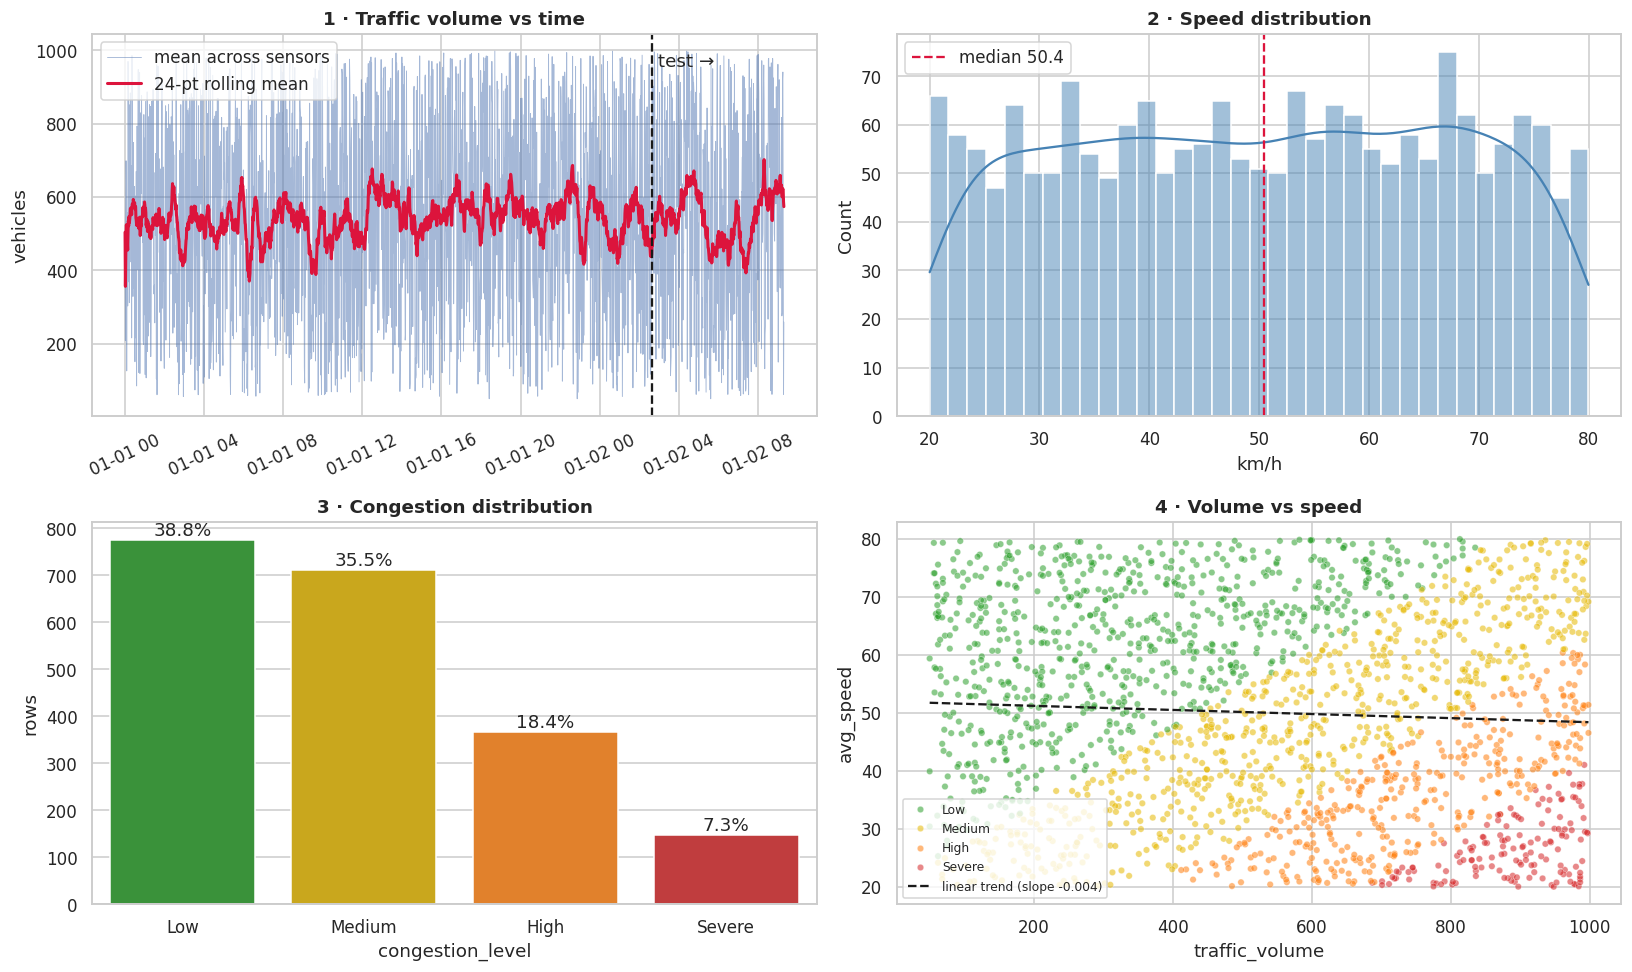

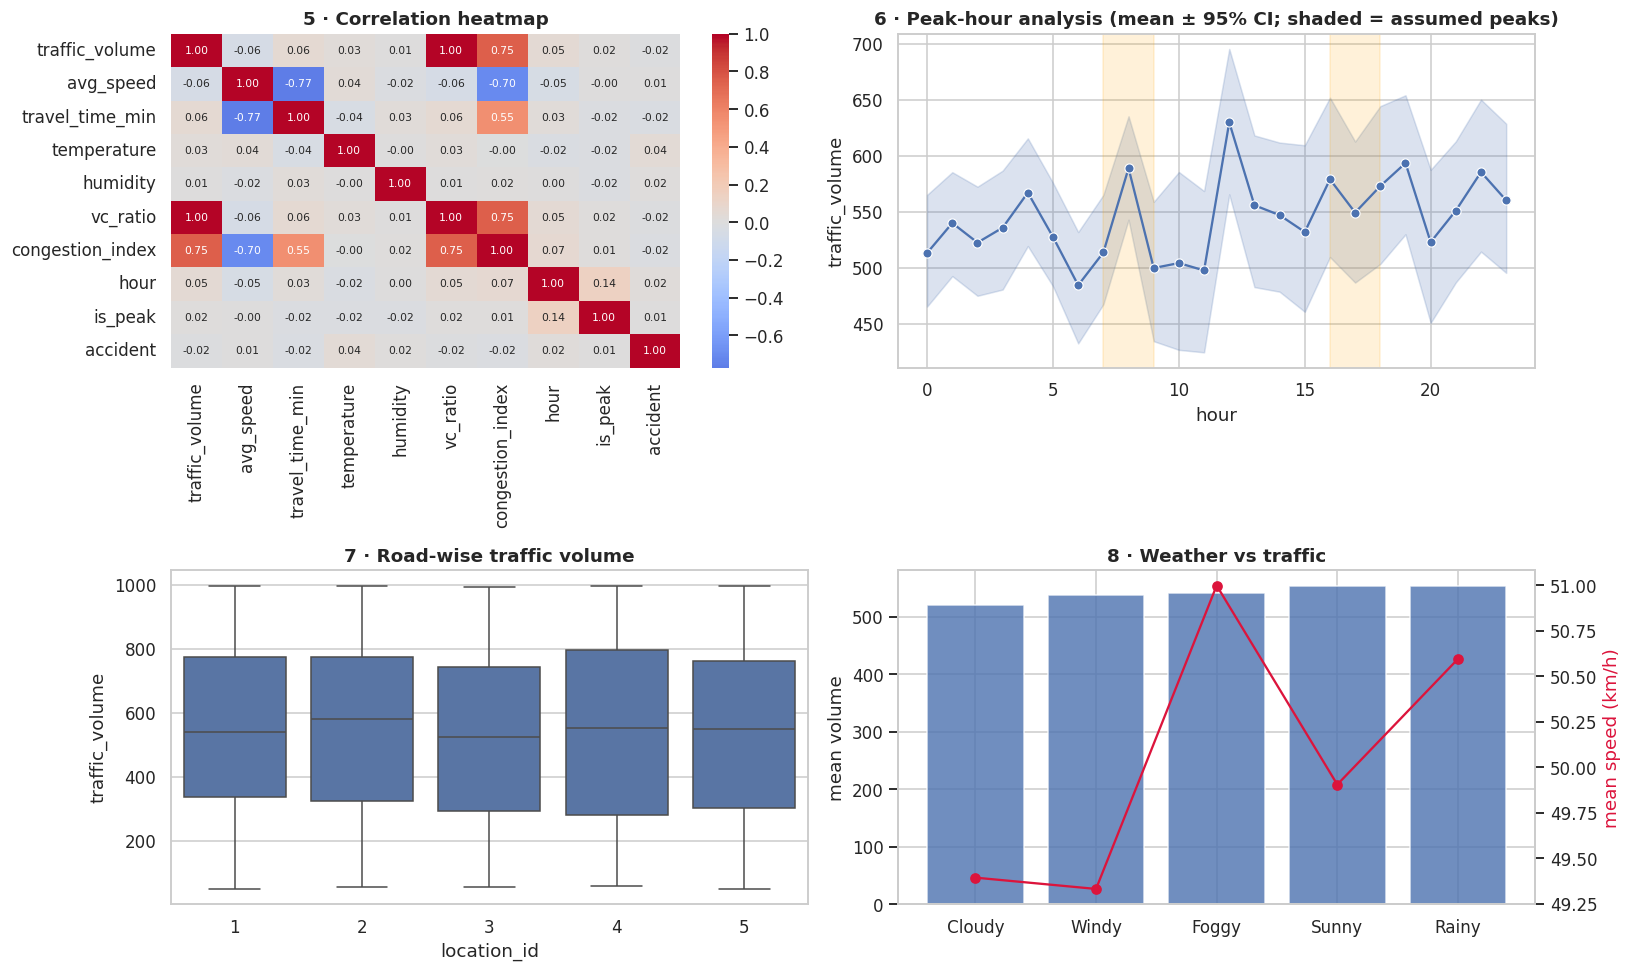

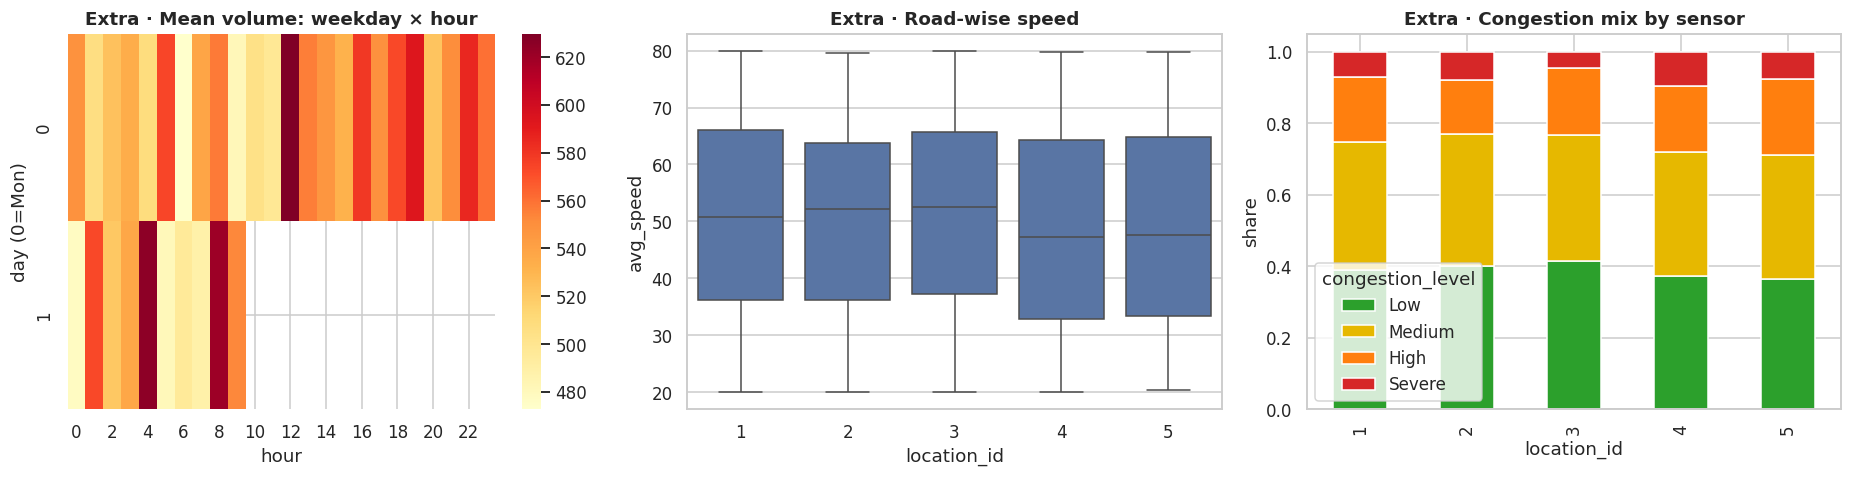

In [ ]:
CONG_COLORS = {'Low': '#2ca02c', 'Medium': '#e6b800', 'High': '#ff7f0e', 'Severe': '#d62728'}
fig, ax = plt.subplots(2, 2, figsize=(15, 9))
tv = d.groupby('timestamp').traffic_volume.mean()
ax[0, 0].plot(tv.index, tv.values, lw=.6, alpha=.5, label='mean across sensors')
ax[0, 0].plot(tv.index, tv.rolling(24, min_periods=1).mean(), lw=2, color='crimson', label='24-pt rolling mean')
ax[0, 0].axvline(CUT_TS, ls='--', c='k'); ax[0, 0].text(CUT_TS, ax[0, 0].get_ylim()[1] * .95, ' test →', va='top')
ax[0, 0].set(title='1 · Traffic volume vs time', ylabel='vehicles'); ax[0, 0].legend(); ax[0, 0].tick_params(axis='x', rotation=25)
sns.histplot(d.avg_speed, kde=True, bins=35, ax=ax[0, 1], color='steelblue')
ax[0, 1].axvline(d.avg_speed.median(), c='crimson', ls='--', label=f'median {d.avg_speed.median():.1f}'); ax[0, 1].legend()
ax[0, 1].set(title='2 · Speed distribution', xlabel='km/h')
cnt = d.congestion_level.value_counts().reindex(LEVELS)
sns.barplot(x=cnt.index, y=cnt.values, palette=[CONG_COLORS[l] for l in LEVELS], ax=ax[1, 0])
for i, v in enumerate(cnt.values): ax[1, 0].text(i, v, f'{100 * v / cnt.sum():.1f}%', ha='center', va='bottom')
ax[1, 0].set(title='3 · Congestion distribution', ylabel='rows')
sns.scatterplot(data=d, x='traffic_volume', y='avg_speed', hue='congestion_level', hue_order=LEVELS,
                palette=CONG_COLORS, alpha=.55, s=18, ax=ax[1, 1])
z = np.polyfit(d.traffic_volume, d.avg_speed, 1); xs = np.linspace(d.traffic_volume.min(), d.traffic_volume.max(), 50)
ax[1, 1].plot(xs, np.polyval(z, xs), 'k--', label=f'linear trend (slope {z[0]:.3f})'); ax[1, 1].legend(fontsize=8)
ax[1, 1].set(title='4 · Volume vs speed')
plt.tight_layout(); show('eda_1_core')

fig, ax = plt.subplots(2, 2, figsize=(15, 9))
cm = d[['traffic_volume', 'avg_speed', 'travel_time_min', 'temperature', 'humidity', 'vc_ratio', 'congestion_index', 'hour', 'is_peak', 'accident']].corr()
sns.heatmap(cm, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax[0, 0], annot_kws={'size': 7}); ax[0, 0].set_title('5 · Correlation heatmap')
sns.lineplot(data=d, x='hour', y='traffic_volume', errorbar=('ci', 95), marker='o', ax=ax[0, 1])
for a, b in [(7, 9), (16, 18)]: ax[0, 1].axvspan(a, b, color='orange', alpha=.15)
ax[0, 1].set(title='6 · Peak-hour analysis (mean ± 95% CI; shaded = assumed peaks)')
sns.boxplot(data=d, x='location_id', y='traffic_volume', order=LOCS, ax=ax[1, 0]); ax[1, 0].set_title('7 · Road-wise traffic volume')
wx = d.groupby('weather').agg(vol=('traffic_volume', 'mean'), spd=('avg_speed', 'mean')).sort_values('vol')
ax[1, 1].bar(wx.index, wx.vol, color='#4c72b0', alpha=.8); ax[1, 1].set_ylabel('mean volume')
ax2 = ax[1, 1].twinx(); ax2.plot(wx.index, wx.spd, 'o-', color='crimson'); ax2.set_ylabel('mean speed (km/h)', color='crimson'); ax2.grid(False)
ax[1, 1].set_title('8 · Weather vs traffic')
plt.tight_layout(); show('eda_2_relationships')

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
hm = d.pivot_table(index='dow', columns='hour', values='traffic_volume', aggfunc='mean')
sns.heatmap(hm, cmap='YlOrRd', ax=ax[0]); ax[0].set(title='Extra · Mean volume: weekday × hour', ylabel='day (0=Mon)')
sns.boxplot(data=d, x='location_id', y='avg_speed', order=LOCS, ax=ax[1]); ax[1].set_title('Extra · Road-wise speed')
share = pd.crosstab(d.location_id, d.congestion_level, normalize='index').reindex(LOCS)[LEVELS]
share.plot(kind='bar', stacked=True, color=[CONG_COLORS[l] for l in LEVELS], ax=ax[2]); ax[2].set(title='Extra · Congestion mix by sensor', ylabel='share')
plt.tight_layout(); show('eda_3_extras')

## 5 · Regression — traffic volume, speed, travel time
* **Time-aware** 80/20 split + `TimeSeriesSplit` cross-validation (no shuffling, no future leakage).
* Six models per target incl. a **mean baseline**; a tuned `HistGradientBoosting` (randomized search) is added.
* The "best" model is chosen by **cross-validated RMSE on the training period**; test metrics (MAE, MSE, RMSE, R²) are the final honest estimate.
* **Leakage control:** the volume model sees only context (time/weather/signal/…); speed & travel-time models may also use observed volume and vehicle mix, but never the speed-derived quantities.

### Target: `traffic_volume`

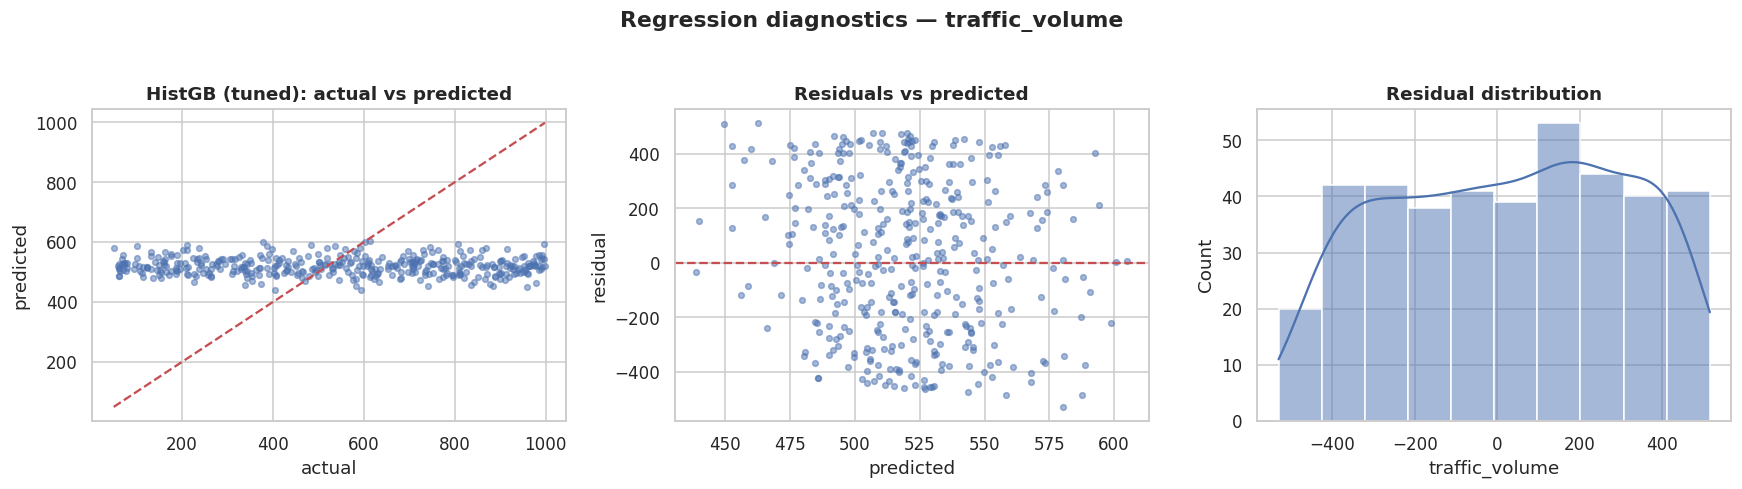

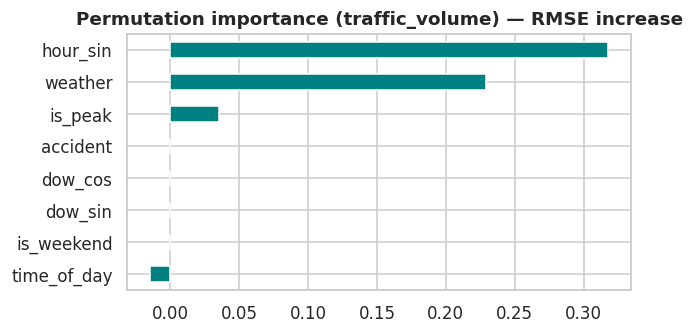

,Model,CV_RMSE,MAE,MSE,RMSE,R2,skill_vs_baseline_%
0,Baseline (mean),272.7089,242.4718,78054.9045,279.3831,-0.0003,0.0000
1,HistGB (tuned),279.8015,245.2109,80227.3587,283.2443,-0.0282,-1.3821
2,Random Forest,286.3157,252.4015,86488.2817,294.0889,-0.1084,-5.2637
3,Gradient Boosting,286.3881,248.9465,83499.5860,288.9629,-0.0701,-3.4289
4,Ridge,294.2481,245.1109,80005.0240,282.8516,-0.0253,-1.2415
5,Linear Regression,295.2669,245.0844,79992.6652,282.8297,-0.0252,-1.2337
6,HistGradientBoosting,307.8186,269.0016,99834.6340,315.9662,-0.2794,-13.0942


➡️ Best (by CV): HistGB (tuned) | test RMSE=283.244, R²=-0.028
⚠️ Weak signal: the available features explain little of this target on unseen (later) data. That is a property of the dataset, reported honestly — not a coding error.


### Target: `avg_speed`

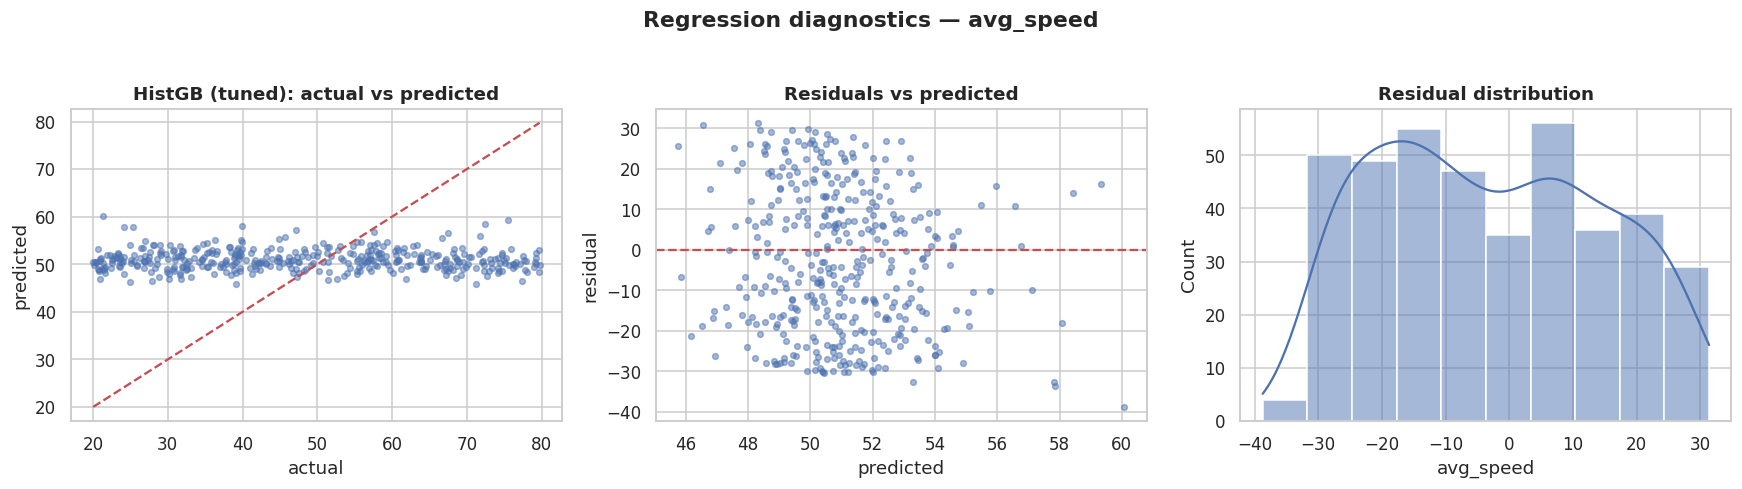

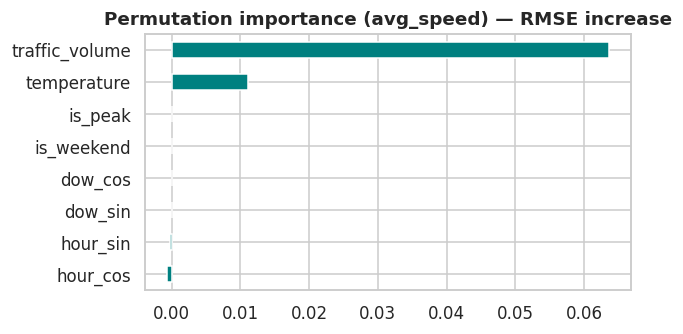

,Model,CV_RMSE,MAE,MSE,RMSE,R2,skill_vs_baseline_%
0,Baseline (mean),17.1691,15.4310,311.2966,17.6436,-0.0232,0.0000
1,HistGB (tuned),17.5382,15.5401,319.6682,17.8793,-0.0507,-1.3357
2,Random Forest,17.6386,15.7780,332.2227,18.2270,-0.0920,-3.3064
3,Gradient Boosting,18.1638,15.7697,335.2133,18.3088,-0.1018,-3.7704
4,HistGradientBoosting,18.9297,16.4067,374.1509,19.3430,-0.2298,-9.6317
5,Ridge,22.0392,15.5615,321.2630,17.9238,-0.0560,-1.5882
6,Linear Regression,22.2473,15.5558,320.9927,17.9163,-0.0551,-1.5454


➡️ Best (by CV): HistGB (tuned) | test RMSE=17.879, R²=-0.051
⚠️ Weak signal: the available features explain little of this target on unseen (later) data. That is a property of the dataset, reported honestly — not a coding error.


### Target: `travel_time_min`

In [ ]:
CAT_FEATS = ['location_id', 'weather', 'signal_status', 'time_of_day']
CTX_NUM = ['hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'is_weekend', 'is_peak', 'temperature', 'humidity', 'accident']
TRAFFIC_NUM = ['traffic_volume', 'truck_share', 'bike_share']
REG_FEATS = {'traffic_volume': CTX_NUM, 'avg_speed': CTX_NUM + TRAFFIC_NUM, 'travel_time_min': CTX_NUM + TRAFFIC_NUM}

tr, te = d[d.is_train], d[~d.is_train]
tscv = TimeSeriesSplit(n_splits=4)

def make_prep(num, cat):
    return ColumnTransformer([('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), num),
                              ('cat', OneHotEncoder(handle_unknown='ignore'), cat)])

def reg_metrics(y, p):
    mse = mean_squared_error(y, p)
    return {'MAE': mean_absolute_error(y, p), 'MSE': mse, 'RMSE': math.sqrt(mse), 'R2': r2_score(y, p)}

def reg_models():
    return {'Baseline (mean)': DummyRegressor(),
            'Linear Regression': LinearRegression(),
            'Ridge': Ridge(alpha=1.0),
            'Random Forest': RandomForestRegressor(n_estimators=250, min_samples_leaf=3, n_jobs=-1, random_state=SEED),
            'Gradient Boosting': GradientBoostingRegressor(random_state=SEED),
            'HistGradientBoosting': HistGradientBoostingRegressor(random_state=SEED)}

def run_regression(target, show_plots=True):
    feats = REG_FEATS[target]; cols = feats + CAT_FEATS
    Xtr, ytr, Xte, yte = tr[cols], tr[target], te[cols], te[target]
    pipes, rows = {}, []
    for name, model in reg_models().items():
        pipe = Pipeline([('prep', make_prep(feats, CAT_FEATS)), ('model', model)])
        cv = -cross_val_score(pipe, Xtr, ytr, cv=tscv, scoring='neg_root_mean_squared_error', error_score=np.nan)
        pipe.fit(Xtr, ytr); pipes[name] = pipe
        rows.append({'Model': name, 'CV_RMSE': np.nanmean(cv), **reg_metrics(yte, pipe.predict(Xte))})
    # hyper-parameter tuning (time-aware CV)
    search = RandomizedSearchCV(
        Pipeline([('prep', make_prep(feats, CAT_FEATS)), ('model', HistGradientBoostingRegressor(random_state=SEED))]),
        {'model__learning_rate': [.03, .05, .1], 'model__max_depth': [3, 4, 6, None], 'model__max_leaf_nodes': [15, 31],
         'model__min_samples_leaf': [10, 20, 40], 'model__l2_regularization': [0, .1, 1]},
        n_iter=12, cv=tscv, scoring='neg_root_mean_squared_error', random_state=SEED, error_score=np.nan)
    search.fit(Xtr, ytr); pipes['HistGB (tuned)'] = search.best_estimator_
    rows.append({'Model': 'HistGB (tuned)', 'CV_RMSE': -search.best_score_, **reg_metrics(yte, search.best_estimator_.predict(Xte))})
    table = pd.DataFrame(rows).sort_values('CV_RMSE').reset_index(drop=True)
    base_rmse = table.loc[table.Model == 'Baseline (mean)', 'RMSE'].iloc[0]
    table['skill_vs_baseline_%'] = 100 * (1 - table.RMSE / base_rmse)
    cand = table[table.Model != 'Baseline (mean)']
    best_name = cand.iloc[0].Model; best = pipes[best_name]
    pred = best.predict(Xte)
    joblib.dump(best, f'{ROOT}/models/regression/{target}__{best_name.replace(" ", "_")}.joblib')
    if show_plots:
        fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
        ax[0].scatter(yte, pred, s=14, alpha=.5); lim = [min(yte.min(), pred.min()), max(yte.max(), pred.max())]
        ax[0].plot(lim, lim, 'r--'); ax[0].set(title=f'{best_name}: actual vs predicted', xlabel='actual', ylabel='predicted')
        ax[1].scatter(pred, yte - pred, s=14, alpha=.5); ax[1].axhline(0, c='r', ls='--'); ax[1].set(title='Residuals vs predicted', xlabel='predicted', ylabel='residual')
        sns.histplot(yte - pred, kde=True, ax=ax[2]); ax[2].set(title='Residual distribution')
        plt.suptitle(f'Regression diagnostics — {target}', y=1.03, fontweight='bold'); plt.tight_layout(); show(f'reg_{target}')
        pi = permutation_importance(best, Xte, yte, n_repeats=8, random_state=SEED, scoring='neg_root_mean_squared_error')
        imp = pd.Series(pi.importances_mean, index=cols).sort_values(ascending=True).tail(8)
        plt.figure(figsize=(6, 3.2)); imp.plot.barh(color='teal'); plt.title(f'Permutation importance ({target}) — RMSE increase'); plt.tight_layout(); show(f'imp_{target}')
    return {'table': table, 'pipe': best, 'name': best_name, 'feats': feats, 'cols': cols, 'pred': pred, 'target': target}

REG = {}
for tgt in ['traffic_volume', 'avg_speed', 'travel_time_min']:
    md_out(f'### Target: `{tgt}`')
    REG[tgt] = run_regression(tgt)
    display(REG[tgt]['table'].round(4))
    b = REG[tgt]['table'].loc[REG[tgt]['table'].Model == REG[tgt]['name']].iloc[0]
    print(f"➡️ Best (by CV): {REG[tgt]['name']} | test RMSE={b.RMSE:.3f}, R²={b.R2:.3f}")
    if b.R2 < 0.10:
        print('⚠️ Weak signal: the available features explain little of this target on unseen (later) data. '
              'That is a property of the dataset, reported honestly — not a coding error.')

## 6 · Congestion classification (Low / Medium / High / Severe)
Two operating modes are compared: **Forecast** (context only — predict before traffic is observed) and **Nowcast** (context + observed volume). Class imbalance is handled with `class_weight='balanced'`.

### Mode: **forecast** (context only)

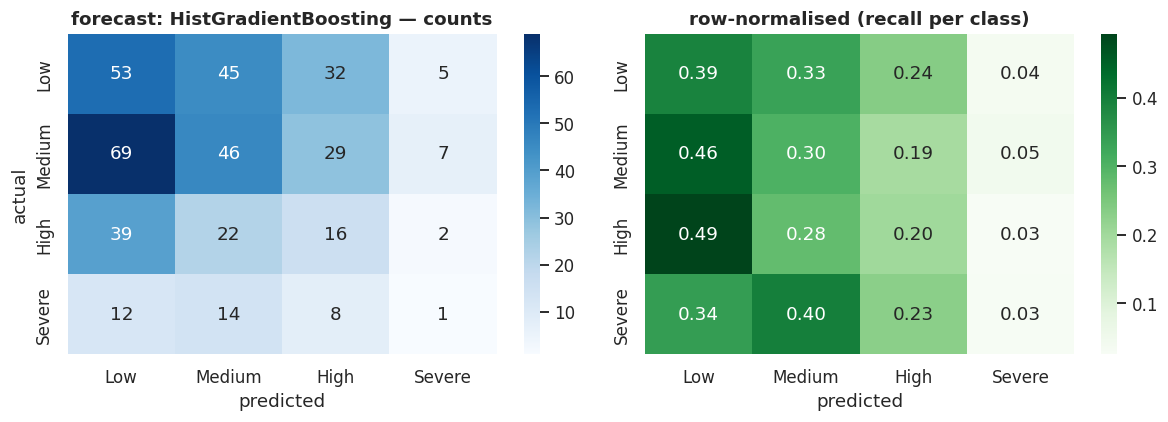

              precision    recall  f1-score   support

         Low       0.31      0.39      0.34       135
      Medium       0.36      0.30      0.33       151
        High       0.19      0.20      0.20        79
      Severe       0.07      0.03      0.04        35

    accuracy                           0.29       400
   macro avg       0.23      0.23      0.23       400
weighted avg       0.28      0.29      0.28       400



,Model,CV_F1_macro,Accuracy,Precision(macro),Recall(macro),F1(macro),F1(weighted),BalancedAcc,ROC_AUC(ovr)
0,HistGradientBoosting,0.2385,0.2900,0.2309,0.2321,0.2276,0.2831,0.2321,0.4987
1,Random Forest,0.2291,0.3350,0.2881,0.2527,0.2315,0.2994,0.2527,0.4986
2,Decision Tree,0.2203,0.2700,0.2909,0.3022,0.2575,0.2719,0.3022,0.5302
3,KNN (k=15),0.1995,0.3350,0.2130,0.2472,0.1906,0.2576,0.2472,0.4892
4,Logistic Regression,0.1860,0.2550,0.2624,0.2788,0.2318,0.2379,0.2788,0.5121
5,Baseline (majority),0.1421,0.3375,0.0844,0.2500,0.1262,0.1703,0.2500,0.5000


➡️ Best (by CV): HistGradientBoosting | test macro-F1 = 0.228


### Mode: **nowcast** (context + observed volume)

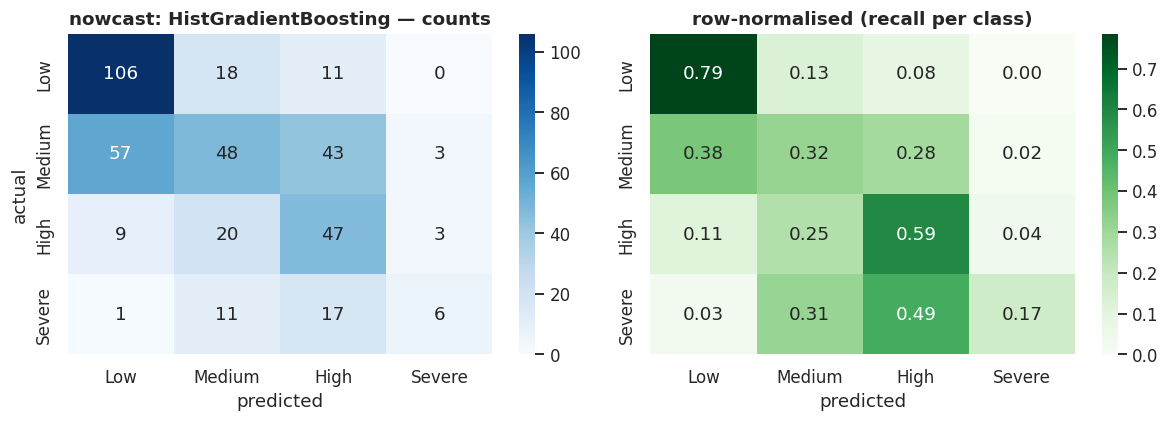

              precision    recall  f1-score   support

         Low       0.61      0.79      0.69       135
      Medium       0.49      0.32      0.39       151
        High       0.40      0.59      0.48        79
      Severe       0.50      0.17      0.26        35

    accuracy                           0.52       400
   macro avg       0.50      0.47      0.45       400
weighted avg       0.52      0.52      0.50       400



,Model,CV_F1_macro,Accuracy,Precision(macro),Recall(macro),F1(macro),F1(weighted),BalancedAcc,ROC_AUC(ovr)
0,HistGradientBoosting,0.3923,0.5175,0.5015,0.4674,0.4520,0.4950,0.4674,0.7795
1,Decision Tree,0.3909,0.5025,0.4725,0.5378,0.4849,0.4918,0.5378,0.7368
2,Random Forest,0.3842,0.4850,0.4260,0.4092,0.3734,0.4459,0.4092,0.7732
3,Logistic Regression,0.3639,0.4850,0.4387,0.5028,0.4494,0.4579,0.5028,0.7736
4,KNN (k=15),0.3040,0.4500,0.3146,0.3591,0.3152,0.3940,0.3591,0.6874
5,Baseline (majority),0.1421,0.3375,0.0844,0.2500,0.1262,0.1703,0.2500,0.5000


➡️ Best (by CV): HistGradientBoosting | test macro-F1 = 0.452


In [ ]:
CLF_SCEN = {'forecast': CTX_NUM, 'nowcast': CTX_NUM + TRAFFIC_NUM}

def clf_models():
    return {'Baseline (majority)': DummyClassifier(strategy='most_frequent'),
            'Logistic Regression': LogisticRegression(max_iter=3000, class_weight='balanced'),
            'Decision Tree': DecisionTreeClassifier(max_depth=6, min_samples_leaf=5, class_weight='balanced', random_state=SEED),
            'Random Forest': RandomForestClassifier(n_estimators=250, min_samples_leaf=2, class_weight='balanced', n_jobs=-1, random_state=SEED),
            'KNN (k=15)': KNeighborsClassifier(n_neighbors=15),
            'HistGradientBoosting': HistGradientBoostingClassifier(class_weight='balanced', random_state=SEED)}

def run_classification(scen):
    feats = CLF_SCEN[scen]; cols = feats + CAT_FEATS
    Xtr, ytr, Xte, yte = tr[cols], tr.congestion_level, te[cols], te.congestion_level
    pipes, rows = {}, []
    for name, model in clf_models().items():
        pipe = Pipeline([('prep', make_prep(feats, CAT_FEATS)), ('model', model)])
        cv = cross_val_score(pipe, Xtr, ytr, cv=tscv, scoring='f1_macro', error_score=np.nan)
        pipe.fit(Xtr, ytr); pipes[name] = pipe; p = pipe.predict(Xte)
        auc = np.nan
        if hasattr(pipe, 'predict_proba'):
            try: auc = roc_auc_score(yte, pipe.predict_proba(Xte), multi_class='ovr', labels=pipe.classes_)
            except Exception: pass
        rows.append({'Model': name, 'CV_F1_macro': np.nanmean(cv), 'Accuracy': accuracy_score(yte, p),
                     'Precision(macro)': precision_score(yte, p, average='macro', zero_division=0),
                     'Recall(macro)': recall_score(yte, p, average='macro', zero_division=0),
                     'F1(macro)': f1_score(yte, p, average='macro', zero_division=0),
                     'F1(weighted)': f1_score(yte, p, average='weighted', zero_division=0),
                     'BalancedAcc': balanced_accuracy_score(yte, p), 'ROC_AUC(ovr)': auc})
    table = pd.DataFrame(rows).sort_values('CV_F1_macro', ascending=False).reset_index(drop=True)
    cand = table[table.Model != 'Baseline (majority)']
    best_name = cand.iloc[0].Model; best = pipes[best_name]; p = best.predict(Xte)
    joblib.dump(best, f'{ROOT}/models/classification/congestion_{scen}__{best_name.replace(" ", "_")}.joblib')
    labels = [l for l in LEVELS if l in set(yte) | set(p)]
    cmx = confusion_matrix(yte, p, labels=labels)
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    sns.heatmap(cmx, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels, ax=ax[0]); ax[0].set(title=f'{scen}: {best_name} — counts', xlabel='predicted', ylabel='actual')
    sns.heatmap(cmx / cmx.sum(1, keepdims=True).clip(min=1), annot=True, fmt='.2f', cmap='Greens', xticklabels=labels, yticklabels=labels, ax=ax[1]); ax[1].set(title='row-normalised (recall per class)', xlabel='predicted')
    plt.tight_layout(); show(f'clf_confusion_{scen}')
    print(classification_report(yte, p, labels=labels, zero_division=0))
    return {'table': table, 'pipe': best, 'name': best_name, 'feats': feats, 'cols': cols}

CLF = {}
for scen in ['forecast', 'nowcast']:
    md_out(f'### Mode: **{scen}** ({"context only" if scen == "forecast" else "context + observed volume"})')
    CLF[scen] = run_classification(scen)
    display(CLF[scen]['table'].round(4))
    bf1 = CLF[scen]['table'].loc[CLF[scen]['table'].Model == CLF[scen]['name'], 'F1(macro)'].iloc[0]
    print(f"➡️ Best (by CV): {CLF[scen]['name']} | test macro-F1 = {bf1:.3f}")

## 7 · Unsupervised learning: K-Means patterns, PCA, anomaly detection

**K-Means: best k = 2** (max silhouette = 0.223)

,hour,traffic_volume,avg_speed,vc_ratio,temperature,humidity,congestion_index,pattern,rows,peak_share_%
cluster,,,,,,,,,,
0,8.893,298.428,51.611,0.263,22.244,60.078,0.296,P1 (congestion rank 1/2),964,24.793
1,9.968,766.634,48.518,0.675,22.636,60.131,0.522,P2 (congestion rank 2/2),1036,25.193


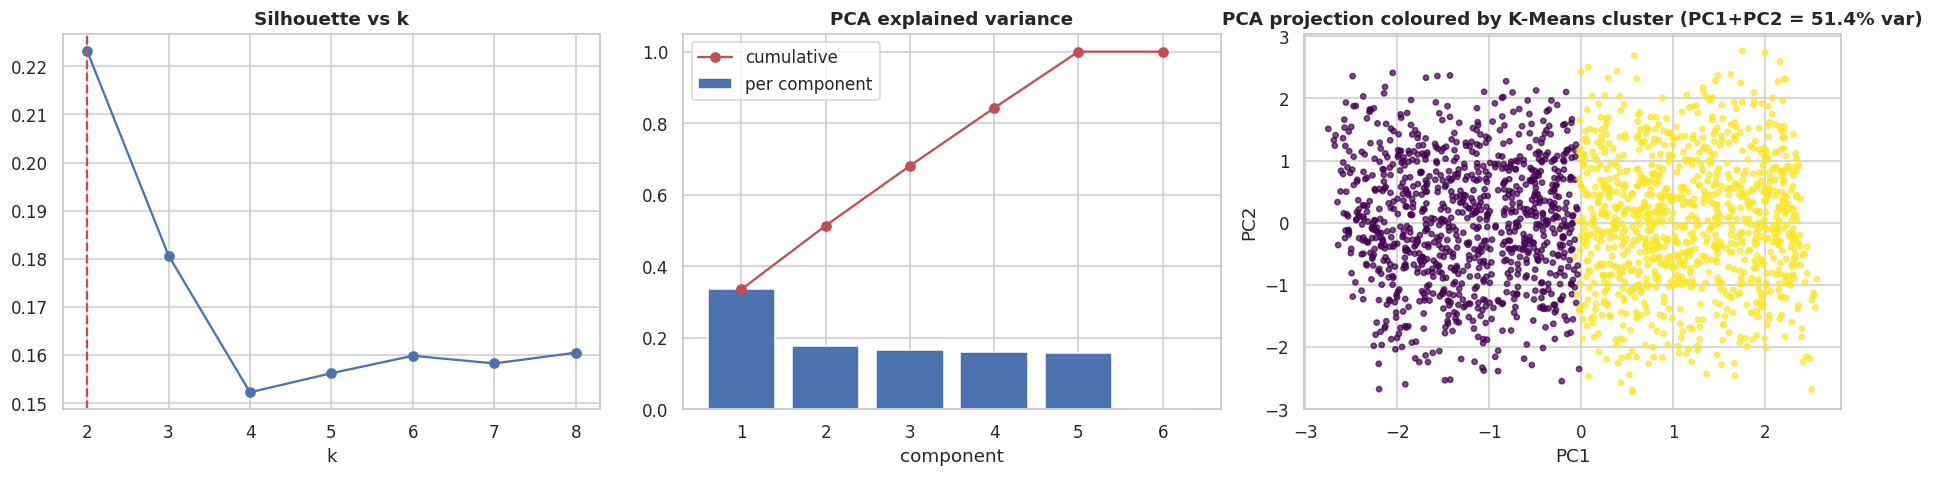

,PC1 loading,PC2 loading
hour,0.072,-0.536
traffic_volume,0.703,0.051
avg_speed,-0.080,0.617
vc_ratio,0.703,0.051
temperature,0.033,0.546
humidity,0.010,-0.170


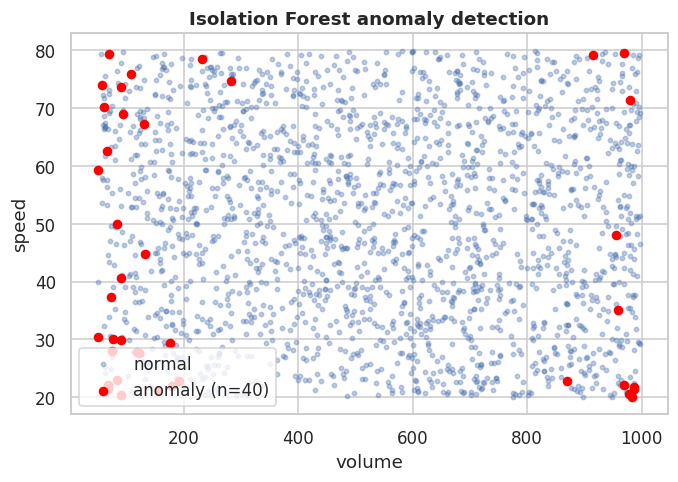

In [ ]:
CL_FEATS = ['hour', 'traffic_volume', 'avg_speed', 'vc_ratio', 'temperature', 'humidity']
Xc = StandardScaler().fit_transform(d[CL_FEATS])
ks = list(range(2, 9)); sil, inertia = [], []
for k in ks:
    km = KMeans(k, n_init=10, random_state=SEED).fit(Xc)
    sil.append(silhouette_score(Xc, km.labels_)); inertia.append(km.inertia_)
K_BEST = ks[int(np.argmax(sil))]
km = KMeans(K_BEST, n_init=20, random_state=SEED).fit(Xc); d['cluster'] = km.labels_
prof = d.groupby('cluster')[CL_FEATS + ['congestion_index']].mean()
rank = prof.congestion_index.rank(method='first').astype(int)
prof['pattern'] = [f'P{rank[c]} (congestion rank {rank[c]}/{K_BEST})' for c in prof.index]
prof['rows'] = d.cluster.value_counts().sort_index(); prof['peak_share_%'] = 100 * d.groupby('cluster').is_peak.mean()
md_out(f'**K-Means: best k = {K_BEST}** (max silhouette = {max(sil):.3f})')
display(prof.sort_values('congestion_index').round(3))

pca = PCA().fit(Xc); Z = pca.transform(Xc)
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ax[0].plot(ks, sil, 'o-'); ax[0].axvline(K_BEST, ls='--', c='r'); ax[0].set(title='Silhouette vs k', xlabel='k')
ax[1].bar(range(1, len(pca.explained_variance_ratio_) + 1), pca.explained_variance_ratio_, label='per component')
ax[1].plot(range(1, len(pca.explained_variance_ratio_) + 1), np.cumsum(pca.explained_variance_ratio_), 'o-r', label='cumulative')
ax[1].set(title='PCA explained variance', xlabel='component'); ax[1].legend()
sc = ax[2].scatter(Z[:, 0], Z[:, 1], c=d.cluster, cmap='viridis', s=12, alpha=.7)
ax[2].set(title=f'PCA projection coloured by K-Means cluster (PC1+PC2 = {100 * pca.explained_variance_ratio_[:2].sum():.1f}% var)', xlabel='PC1', ylabel='PC2')
plt.tight_layout(); show('clustering_pca')
display(pd.DataFrame(pca.components_[:2].T, index=CL_FEATS, columns=['PC1 loading', 'PC2 loading']).round(3))

iso = IsolationForest(contamination=0.02, random_state=SEED).fit(Xc)
d['is_anomaly'] = (iso.predict(Xc) == -1).astype(int)
plt.figure(figsize=(7, 4.5))
plt.scatter(d.traffic_volume, d.avg_speed, s=8, alpha=.35, label='normal')
plt.scatter(d.loc[d.is_anomaly == 1, 'traffic_volume'], d.loc[d.is_anomaly == 1, 'avg_speed'], s=28, c='red', label=f'anomaly (n={int(d.is_anomaly.sum())})')
plt.xlabel('volume'); plt.ylabel('speed'); plt.title('Isolation Forest anomaly detection'); plt.legend(); show('anomalies')

## 8 · Time-series forecasting
Network-average volume is aggregated to a regular series (frequency inferred from the data), split chronologically, and forecast **multi-step** over the whole test window by: Naïve, Seasonal-Naïve, Moving Average, Holt-Winters, an **AIC-selected ARIMA**, and a **recursive lag-feature Gradient-Boosting** model. Reported: MAE, RMSE, MAPE.

Series: 34 points, freq=h, season=24, train=28, horizon=6


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


ARIMA order chosen by AIC: (0, 1, 1) (AIC=278.8)


,MAE,RMSE,MAPE_%
"ARIMA(0, 1, 1)",55.567,60.422,10.184
Moving average (w=24),55.567,60.437,10.162
Holt-Winters,55.567,60.517,10.124
Naive (last value),55.567,60.784,10.064
GBM on lags (recursive),55.567,62.695,9.875
Seasonal naive,69.550,75.663,12.667


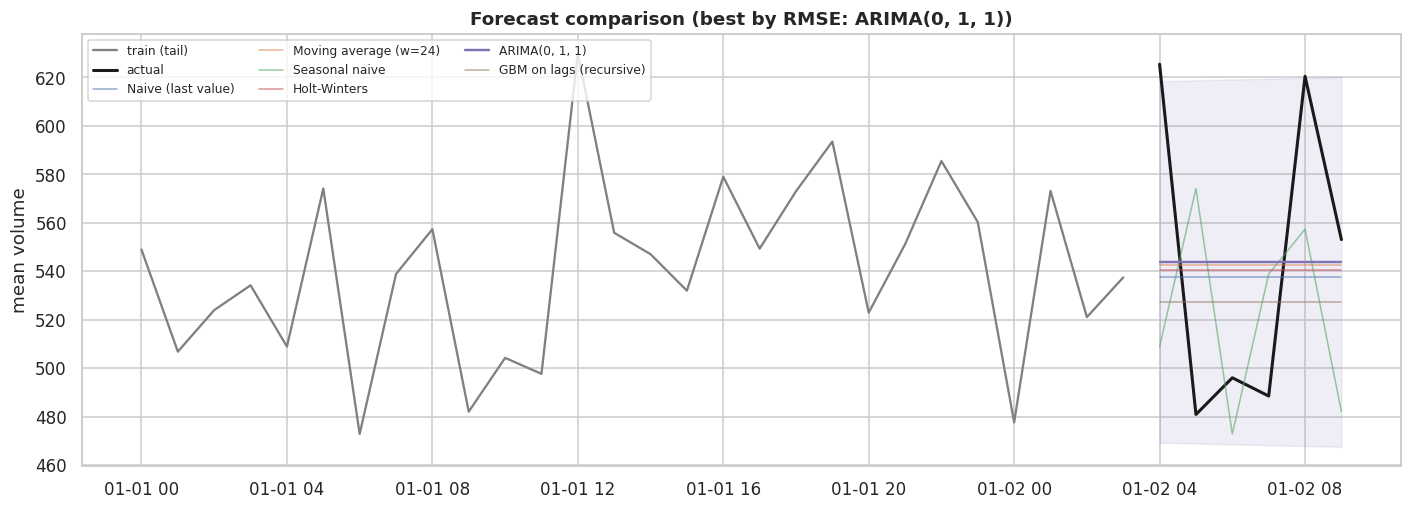

In [ ]:
warnings.simplefilter('ignore')
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.arima.model import ARIMA

ts_raw = d.groupby('timestamp').traffic_volume.mean().sort_index()
gap = ts_raw.index.to_series().diff().dropna().median() if len(ts_raw) > 1 else pd.Timedelta(hours=1)
if len(ts_raw) >= 40 and gap <= pd.Timedelta(minutes=90): FREQ, SEASON = 'h', 24
elif len(ts_raw) >= 40 and gap <= pd.Timedelta(hours=36): FREQ, SEASON = 'D', 7
else: FREQ, SEASON = None, None
if FREQ:
    ts = ts_raw.resample(FREQ).mean().interpolate(limit_direction='both')
else:
    ts = ts_raw.copy(); ts.index = pd.RangeIndex(len(ts))
H = max(int(len(ts) * 0.2), 5)
ts_train, ts_test = ts.iloc[:-H], ts.iloc[-H:]
print(f'Series: {len(ts)} points, freq={FREQ}, season={SEASON}, train={len(ts_train)}, horizon={H}')

def fc_metrics(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    return {'MAE': np.mean(np.abs(y - p)), 'RMSE': math.sqrt(np.mean((y - p) ** 2)), 'MAPE_%': 100 * np.mean(np.abs((y - p) / np.where(y == 0, np.nan, y)))}

forecasts, ci = {}, None
forecasts['Naive (last value)'] = np.repeat(ts_train.iloc[-1], H)
w = SEASON or 6
forecasts[f'Moving average (w={w})'] = np.repeat(ts_train.iloc[-w:].mean(), H)
if SEASON and len(ts_train) >= SEASON:
    forecasts['Seasonal naive'] = np.array([ts_train.iloc[-SEASON + (i % SEASON)] for i in range(H)])
try:
    seasonal = 'add' if SEASON and len(ts_train) >= 2 * SEASON else None
    hw = ExponentialSmoothing(ts_train.values, trend=None, seasonal=seasonal, seasonal_periods=SEASON if seasonal else None).fit()
    forecasts['Holt-Winters'] = hw.forecast(H)
except Exception as e: print('Holt-Winters skipped:', e)
try:
    best_aic, best_order = np.inf, None
    for p_, d_, q_ in itertools.product([0, 1, 2], [0, 1], [0, 1, 2]):
        try:
            r = ARIMA(ts_train.values, order=(p_, d_, q_)).fit()
            if r.aic < best_aic: best_aic, best_order, best_fit = r.aic, (p_, d_, q_), r
        except Exception: pass
    fo = best_fit.get_forecast(H); forecasts[f'ARIMA{best_order}'] = fo.predicted_mean; ci = fo.conf_int(alpha=.05)
    print(f'ARIMA order chosen by AIC: {best_order} (AIC={best_aic:.1f})')
except Exception as e: print('ARIMA skipped:', e)
try:
    L = SEASON or 6
    def lag_feats(hist, idx):
        f = {f'lag{k}': hist[-k] for k in range(1, L + 1)}
        if isinstance(idx, pd.Timestamp): f.update(hs=np.sin(2 * np.pi * idx.hour / 24), hc=np.cos(2 * np.pi * idx.hour / 24))
        return f
    vals = list(ts_train.values); Xl, yl = [], []
    for i in range(L, len(vals)):
        Xl.append(lag_feats(vals[:i], ts_train.index[i])); yl.append(vals[i])
    gbm = HistGradientBoostingRegressor(max_depth=4, learning_rate=.05, random_state=SEED).fit(pd.DataFrame(Xl), yl)
    hist, out = list(vals), []
    for i in range(H):
        nxt = float(gbm.predict(pd.DataFrame([lag_feats(hist, ts_test.index[i])]))[0]); out.append(nxt); hist.append(nxt)
    forecasts['GBM on lags (recursive)'] = np.array(out)
    joblib.dump(gbm, f'{ROOT}/models/forecasting/gbm_lag_forecaster.joblib')
except Exception as e: print('Lag-GBM skipped:', e)

fc_table = pd.DataFrame({k: fc_metrics(ts_test.values, v) for k, v in forecasts.items()}).T.sort_values('RMSE')
display(fc_table.round(3))
BEST_FC = fc_table.index[0]
fig, ax = plt.subplots(figsize=(13, 4.8))
ctx = ts_train.iloc[-min(len(ts_train), 3 * (SEASON or 20)):]
ax.plot(ctx.index, ctx.values, c='gray', label='train (tail)'); ax.plot(ts_test.index, ts_test.values, c='k', lw=2, label='actual')
for k, v in forecasts.items(): ax.plot(ts_test.index, v, lw=1.6 if k == BEST_FC else 1, alpha=1 if k == BEST_FC else .6, label=k)
if ci is not None: ax.fill_between(ts_test.index, np.asarray(ci)[:, 0], np.asarray(ci)[:, 1], color='C4', alpha=.12)
ax.set(title=f'Forecast comparison (best by RMSE: {BEST_FC})', ylabel='mean volume'); ax.legend(ncol=3, fontsize=8); plt.tight_layout(); show('forecast_comparison')

## 9 · Search algorithms with a justified ITS role
* **Binary search** works only on **sorted** data — here: (a) timestamp lookup, (b) counting records above a volume threshold, (c) classifying a congestion index against sorted cut-points.
* **Linear search** is the baseline. Both count comparisons and are benchmarked. Binary search is *not* a route-finding method.

(a) first record at/after 2024-01-02 01:00:00: linear=1501 comparisons, binary=10 comparisons
(b) 200 of 2000 records have volume >= 915 (found in 11 comparisons)
(c) binary-search level assignment matches labels for 100.00% of rows


,n,linear_ms,binary_ms,linear_comparisons,binary_comparisons,log2(n)
0,1000,0.100553,0.001691,1000,10,10.0
1,10000,0.999257,0.002705,10000,13,13.3
2,100000,10.234398,0.002794,100000,17,16.6
3,1000000,102.172419,0.005432,1000000,20,19.9


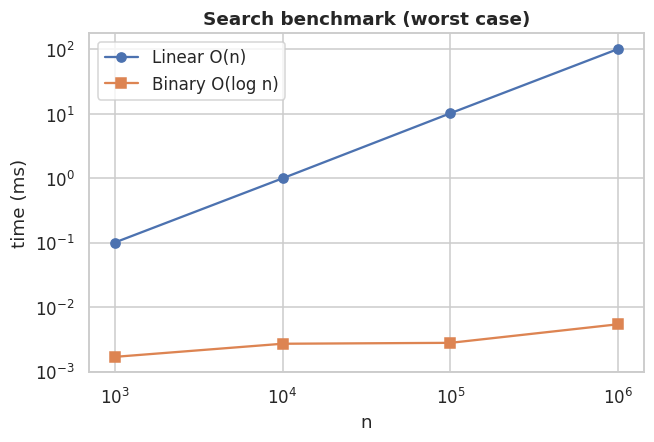

Sanity check — binary search on UNSORTED data is unreliable: (4, 3) (true first >=3 is index 0)


In [ ]:
def linear_first_ge(arr, x):
    comps = 0
    for i, v in enumerate(arr):
        comps += 1
        if v >= x: return i, comps
    return len(arr), comps

def binary_first_ge(arr, x):
    lo, hi, comps = 0, len(arr), 0
    while lo < hi:
        mid = (lo + hi) // 2; comps += 1
        if arr[mid] < x: lo = mid + 1
        else: hi = mid
    return lo, comps

# (a) timestamp lookup on records sorted by time
t_ns = d.timestamp.values.astype('datetime64[ns]').astype('int64').tolist()
target = t_ns[len(t_ns) * 3 // 4]
i_lin, c_lin = linear_first_ge(t_ns, target); i_bin, c_bin = binary_first_ge(t_ns, target)
assert i_lin == i_bin == bisect.bisect_left(t_ns, target)
print(f'(a) first record at/after {d.timestamp.iloc[i_bin]}: linear={c_lin} comparisons, binary={c_bin} comparisons')

# (b) how many observations reach a chosen volume threshold?
vols = sorted(d.traffic_volume.tolist()); thr = float(np.quantile(vols, .90))
idx, c = binary_first_ge(vols, thr); n_above = len(vols) - idx
assert n_above == int((np.array(vols) >= thr).sum())
print(f'(b) {n_above} of {len(vols)} records have volume >= {thr:.0f} (found in {c} comparisons)')

# (c) classify congestion index using sorted cut-points (same thresholds used to build the labels)
cuts = list(q)
pred_lvl = [LEVELS[binary_first_ge(cuts, x)[0]] for x in d.congestion_index]
print(f'(c) binary-search level assignment matches labels for {100 * np.mean(np.array(pred_lvl) == d.congestion_level.values):.2f}% of rows')

# benchmark (worst case: element at the end)
sizes = [10 ** 3, 10 ** 4, 10 ** 5, 10 ** 6]; tl, tb, cl, cb = [], [], [], []
for n in sizes:
    arr = list(range(n)); x = n - 1
    tl.append(timeit.timeit(lambda: linear_first_ge(arr, x), number=3) / 3 * 1e3)
    tb.append(timeit.timeit(lambda: binary_first_ge(arr, x), number=2000) / 2000 * 1e3)
    cl.append(linear_first_ge(arr, x)[1]); cb.append(binary_first_ge(arr, x)[1])
bench = pd.DataFrame({'n': sizes, 'linear_ms': tl, 'binary_ms': tb, 'linear_comparisons': cl, 'binary_comparisons': cb, 'log2(n)': np.log2(sizes).round(1)})
display(bench)
plt.figure(figsize=(6.5, 4)); plt.loglog(sizes, tl, 'o-', label='Linear O(n)'); plt.loglog(sizes, tb, 's-', label='Binary O(log n)')
plt.xlabel('n'); plt.ylabel('time (ms)'); plt.title('Search benchmark (worst case)'); plt.legend(); show('search_benchmark')
print('Sanity check — binary search on UNSORTED data is unreliable:', binary_first_ge([5, 1, 9, 2, 8, 3], 3), '(true first >=3 is index 0)')

## 10 · Road network as a graph
The Kaggle file has **no road geometry**, so the network is a **simulated 16-intersection graph** (Delaunay triangulation of jittered grid points, pruned to look road-like). Every edge (road segment) is wired to one of the dataset's **real sensor locations** through spatial clustering, so ML predictions for that sensor drive the edge's speed, travel time, congestion and risk.

Graph: 16 intersections, 30 road segments, connected = True


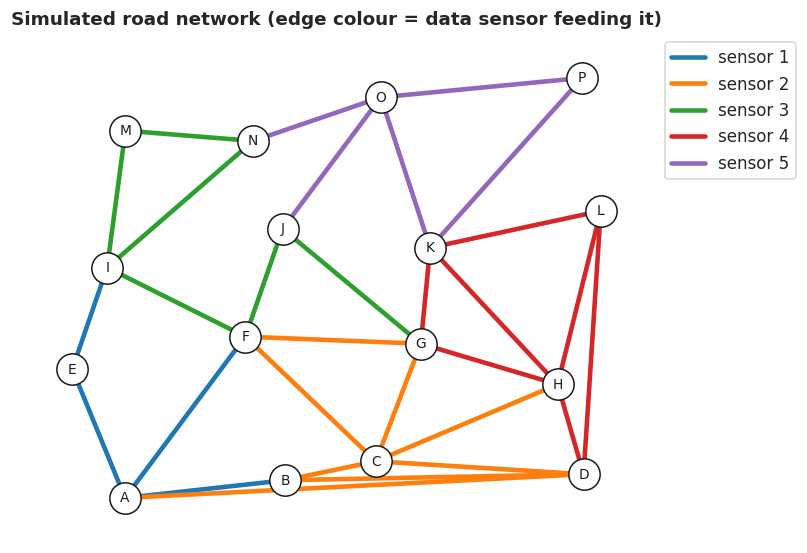

In [ ]:
rng_g = np.random.default_rng(SEED)
N_NODES = 16; NAMES = [chr(65 + i) for i in range(N_NODES)]
POS = {}
for i, n in enumerate(NAMES):
    r_, c_ = divmod(i, 4); POS[n] = (c_ * 3.0 + rng_g.uniform(-.8, .8), r_ * 3.0 + rng_g.uniform(-.8, .8))
def eu(a, b): return float(math.hypot(POS[a][0] - POS[b][0], POS[a][1] - POS[b][1]))

tri = Delaunay(np.array([POS[n] for n in NAMES]))
cand = {tuple(sorted(e)) for s in tri.simplices for e in itertools.combinations(s, 2)}
G0 = nx.Graph(); G0.add_nodes_from(NAMES)
for a, b in cand: G0.add_edge(NAMES[a], NAMES[b])
for a, b in sorted(list(G0.edges), key=lambda e: -eu(*e)):            # prune long edges, keep connectivity
    if rng_g.random() < .22 and G0.degree[a] > 2 and G0.degree[b] > 2:
        G0.remove_edge(a, b)
        if not nx.is_connected(G0): G0.add_edge(a, b)

edges = list(G0.edges)
mid = np.array([[(POS[u][0] + POS[v][0]) / 2, (POS[u][1] + POS[v][1]) / 2] for u, v in edges])
kmg = KMeans(min(len(LOCS), len(edges)), n_init=10, random_state=SEED).fit(mid)
order = np.argsort(kmg.cluster_centers_.sum(1)); cl2loc = {int(c): LOCS[i] for i, c in enumerate(order)}
for (u, v), cl_ in zip(edges, kmg.labels_):
    G0[u][v].update(euclid=eu(u, v), length=eu(u, v) * float(rng_g.uniform(1.05, 1.30)), location_id=cl2loc[int(cl_)])
print(f'Graph: {G0.number_of_nodes()} intersections, {G0.number_of_edges()} road segments, connected = {nx.is_connected(G0)}')

plt.figure(figsize=(7.5, 6))
pal = dict(zip(LOCS, sns.color_palette('tab10', len(LOCS))))
nx.draw_networkx_edges(G0, POS, edge_color=[pal[G0[u][v]['location_id']] for u, v in G0.edges], width=3)
nx.draw_networkx_nodes(G0, POS, node_color='white', edgecolors='k', node_size=420); nx.draw_networkx_labels(G0, POS, font_size=9)
plt.legend(handles=[plt.Line2D([0], [0], color=pal[l], lw=3, label=f'sensor {l}') for l in LOCS], loc='upper left', bbox_to_anchor=(1, 1))
plt.title('Simulated road network (edge colour = data sensor feeding it)'); plt.axis('off'); show('road_graph_base')

### 10.1 Turning ML predictions into edge costs (Traffic Intelligence layer)
For a scenario (hour, weekday, weather, …) the pipeline **chains the models per sensor**: volume model → speed / travel-time models (using predicted volume) → congestion classifier (nowcast mode).

**Route cost per edge** (blueprint §10, with congestion/risk scaled by segment length so long segments weigh more):

`cost = α·distance + β·travel_time + γ·(congestion_penalty × distance) + δ·(risk × distance)`

Congestion penalty: Low 0 · Medium 1 · High 3 · Severe 6. Risk = historical accident rate of the sensor (normalised) + 0.5 in rain/fog/snow + 1 if an incident is active.

In [ ]:
CONG_PENALTY = {'Low': 0.0, 'Medium': 1.0, 'High': 3.0, 'Severe': 6.0}
RISKY = re.compile('rain|fog|snow|storm|ice|hail|mist|drizzle', re.I)
DAY_TO_DOW = {n: i for i, n in enumerate(['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'])}
DEFAULT_W = dict(alpha=0.3, beta=1.0, gamma=1.0, delta=1.0)
WEATHERS = sorted(d.weather.unique())
DEFAULT_WEATHER = 'Rainy' if 'Rainy' in WEATHERS else d.weather.mode()[0]
_max_acc = max(loc_stats.accident_rate.max(), 1e-9)

def scenario_table(hour, day, weather, temperature=None, humidity=None, signal=None, accident=0):
    sub = d[d.weather == weather]
    temperature = float(sub.temperature.median() if temperature is None and len(sub) else d.temperature.median() if temperature is None else temperature)
    humidity = float(sub.humidity.median() if humidity is None and len(sub) else d.humidity.median() if humidity is None else humidity)
    signal = signal or d.signal_status.mode()[0]; dow = DAY_TO_DOW[day]
    X = pd.DataFrame({'location_id': LOCS, 'weather': weather, 'signal_status': signal, 'time_of_day': tod(hour),
                      'hour_sin': np.sin(2 * np.pi * hour / 24), 'hour_cos': np.cos(2 * np.pi * hour / 24),
                      'dow_sin': np.sin(2 * np.pi * dow / 7), 'dow_cos': np.cos(2 * np.pi * dow / 7),
                      'is_weekend': int(dow >= 5), 'is_peak': int(hour in [7, 8, 9, 16, 17, 18]),
                      'temperature': temperature, 'humidity': humidity, 'accident': accident})
    X['traffic_volume'] = np.clip(REG['traffic_volume']['pipe'].predict(X[REG['traffic_volume']['cols']]), 0, None)
    X['truck_share'] = loc_stats.truck_share.reindex(LOCS).values; X['bike_share'] = loc_stats.bike_share.reindex(LOCS).values
    speed = np.clip(REG['avg_speed']['pipe'].predict(X[REG['avg_speed']['cols']]), 5, 130)
    tt = np.clip(REG['travel_time_min']['pipe'].predict(X[REG['travel_time_min']['cols']]), 0.05, None)
    level = CLF['nowcast']['pipe'].predict(X[CLF['nowcast']['cols']])
    risk = loc_stats.accident_rate.reindex(LOCS).values / _max_acc + (0.5 if RISKY.search(weather) else 0.0) + accident
    return pd.DataFrame({'pred_volume': X.traffic_volume.values, 'pred_speed_kmh': speed,
                         'tt_min_per_km': tt / SEG_KM.reindex(LOCS).values, 'level': level, 'risk': risk}, index=LOCS)

def annotate(G_base, scen, W, incidents=frozenset()):
    G = G_base.copy()
    for u, v, e in G.edges(data=True):
        s = scen.loc[e['location_id']]; time_ = s.tt_min_per_km * e['length']; speed = s.pred_speed_kmh; lvl = s.level; risk = s.risk
        if frozenset((u, v)) in incidents:                       # simulated incident: slow, severe, riskier
            time_ *= 3.0; speed /= 3.0; lvl = 'Severe'; risk += 1.0
        e.update(dist=e['length'], time=time_, speed=speed, level=lvl, cong=CONG_PENALTY[lvl] * e['length'], risk=risk * e['length'])
        e['cost'] = W['alpha'] * e['dist'] + W['beta'] * e['time'] + W['gamma'] * e['cong'] + W['delta'] * e['risk']
    return G

SC0 = dict(hour=17, day='Thursday', weather=DEFAULT_WEATHER)
scen0 = scenario_table(**SC0); G_lab = annotate(G0, scen0, DEFAULT_W)
md_out(f'**Baseline scenario for the labs:** {SC0}')
display(scen0.round(3))

**Baseline scenario for the labs:** {'hour': 17, 'day': 'Thursday', 'weather': 'Rainy'}

,pred_volume,pred_speed_kmh,tt_min_per_km,level,risk
1,557.146,50.554,1.345,Medium,1.006
2,547.107,50.554,1.399,Medium,1.500
3,538.357,50.554,1.291,Medium,1.082
4,547.107,50.153,1.434,Low,1.316
5,547.107,50.554,1.452,Medium,1.482


## 11 · BFS, DFS, Dijkstra and A* (implemented from scratch)
| Algorithm | Role here |
|---|---|
| **BFS** | minimum-**hop** route on the unweighted graph (not fastest) |
| **DFS** | traversal / connectivity / reachability (no shortest-path guarantee) |
| **A\*** | primary router: `f(n) = g(n) + h(n)` |
| **Dijkstra** | A\* with `h = 0` — optimality reference |

**Admissible heuristic:** `h(n) = (α + β·t_min)·straight_line(n, goal)` where `t_min` is the smallest minutes-per-km currently on the network. Congestion/risk terms are ≥ 0 and every road is at least as long as the straight line, so `h` never overestimates → A\* returns the same cost as Dijkstra (asserted below).

In [ ]:
def _path(parent, t):
    p = []
    while t is not None: p.append(t); t = parent[t]
    return p[::-1]

def bfs(G, s, t):
    t0 = time.perf_counter(); q = deque([s]); parent = {s: None}; expanded = 0
    while q:
        u = q.popleft(); expanded += 1
        if u == t: break
        for v in sorted(G[u]):
            if v not in parent: parent[v] = u; q.append(v)
    return dict(path=_path(parent, t) if t in parent else None, expanded=expanded, generated=len(parent), runtime_ms=(time.perf_counter() - t0) * 1e3)

def dfs(G, s, t):
    t0 = time.perf_counter(); stack = [(s, None)]; visited, parent = set(), {}; expanded = 0
    while stack:
        u, p = stack.pop()
        if u in visited: continue
        visited.add(u); parent[u] = p; expanded += 1
        if u == t: break
        for v in sorted(G[u], reverse=True):
            if v not in visited: stack.append((v, u))
    return dict(path=_path(parent, t) if t in parent else None, expanded=expanded, generated=len(visited), runtime_ms=(time.perf_counter() - t0) * 1e3)

def dfs_components(G):
    seen, comps = set(), []
    for n in G:
        if n in seen: continue
        comp, stack = [], [n]
        while stack:
            u = stack.pop()
            if u in seen: continue
            seen.add(u); comp.append(u); stack.extend(v for v in G[u] if v not in seen)
        comps.append(sorted(comp))
    return comps

def astar(G, s, t, key='cost', h=None, eps=1.0):
    t0 = time.perf_counter(); h = h or (lambda n: 0.0); cnt = itertools.count()
    g = {s: 0.0}; parent = {s: None}; closed = set(); pq = [(eps * h(s), next(cnt), s)]; expanded, generated = 0, 1
    while pq:
        _, _, u = heapq.heappop(pq)
        if u in closed: continue
        closed.add(u); expanded += 1
        if u == t: break
        for v in G[u]:
            ng = g[u] + G[u][v][key]
            if ng < g.get(v, math.inf):
                g[v] = ng; parent[v] = u; heapq.heappush(pq, (ng + eps * h(v), next(cnt), v)); generated += 1
    return dict(path=_path(parent, t) if t in parent else None, expanded=expanded, generated=generated, runtime_ms=(time.perf_counter() - t0) * 1e3)

def make_h(G, t, mode, W):
    tmin = min(e['time'] / e['dist'] for *_, e in G.edges(data=True))
    if mode == 'cost': return lambda n: (W['alpha'] + W['beta'] * tmin) * eu(n, t)
    if mode == 'dist': return lambda n: eu(n, t)
    return lambda n: 0.0

def evaluate_path(G, path):
    es = [G[u][v] for u, v in zip(path[:-1], path[1:])]
    return dict(hops=len(es), distance_km=sum(e['dist'] for e in es), eta_min=sum(e['time'] for e in es), cost=sum(e['cost'] for e in es),
                n_high_severe=sum(e['level'] in ('High', 'Severe') for e in es))

# ---- correctness checks: A* must equal Dijkstra must equal networkx ----
rng_t = random.Random(SEED); checked = 0
for _ in range(40):
    s_, t_ = rng_t.sample(NAMES, 2)
    a = astar(G_lab, s_, t_, 'cost', make_h(G_lab, t_, 'cost', DEFAULT_W)); dj = astar(G_lab, s_, t_, 'cost')
    ref = nx.dijkstra_path_length(G_lab, s_, t_, weight='cost')
    assert math.isclose(evaluate_path(G_lab, a['path'])['cost'], ref, rel_tol=1e-9) and math.isclose(evaluate_path(G_lab, dj['path'])['cost'], ref, rel_tol=1e-9)
    checked += 1
print(f'✅ {checked} random pairs: A* cost == Dijkstra cost == networkx reference (heuristic is admissible)')

# ---- DFS as connectivity / road-closure analysis ----
print('Components (intact network):', len(dfs_components(G_lab)))
victim = min(G_lab.degree, key=lambda x: x[1])[0]; Gc = G_lab.copy(); Gc.remove_edges_from(list(Gc.edges(victim)))
comps_c = dfs_components(Gc)
print(f'Closing all {G_lab.degree[victim]} roads at intersection {victim} -> {len(comps_c)} components (DFS): sizes {sorted(len(c) for c in comps_c)}; intersection {victim} is isolated: {[victim] in comps_c}')

✅ 40 random pairs: A* cost == Dijkstra cost == networkx reference (heuristic is admissible)
Components (intact network): 1
Closing all 2 roads at intersection E -> 2 components (DFS): sizes [1, 15]; intersection E is isolated: True


## 12 · Algorithm Lab — same graph, every source–destination pair

Averages over **120 node pairs** (costs evaluated under the *same* traffic-aware objective; scenario {'hour': 17, 'day': 'Thursday', 'weather': 'Rainy'}):

,nodes_expanded,nodes_generated,runtime_ms,hops,distance_km,eta_min,route_cost,high_severe_segments,mean_gap_pct,pct_pairs_optimal
method,,,,,,,,,,
BFS (min hops),9.900,13.142,0.013,2.233,9.597,13.275,36.509,0.0,10.303,70.000
DFS (first path found),10.883,10.883,0.017,8.758,34.818,48.415,132.973,0.0,382.937,1.667
Dijkstra (h=0),9.242,13.842,0.040,2.333,8.612,11.940,32.405,0.0,0.000,100.000
A* distance-only,4.200,9.208,0.021,2.308,8.589,11.919,32.554,0.0,0.335,95.000
A* traffic-aware,6.750,11.658,0.039,2.333,8.612,11.940,32.405,0.0,0.000,100.000
A* traffic-aware ε=1.5,5.817,10.850,0.033,2.333,8.612,11.940,32.405,0.0,0.000,100.000
A* traffic-aware ε=3.0,3.808,8.817,0.024,2.350,8.638,11.975,32.433,0.0,0.076,97.500


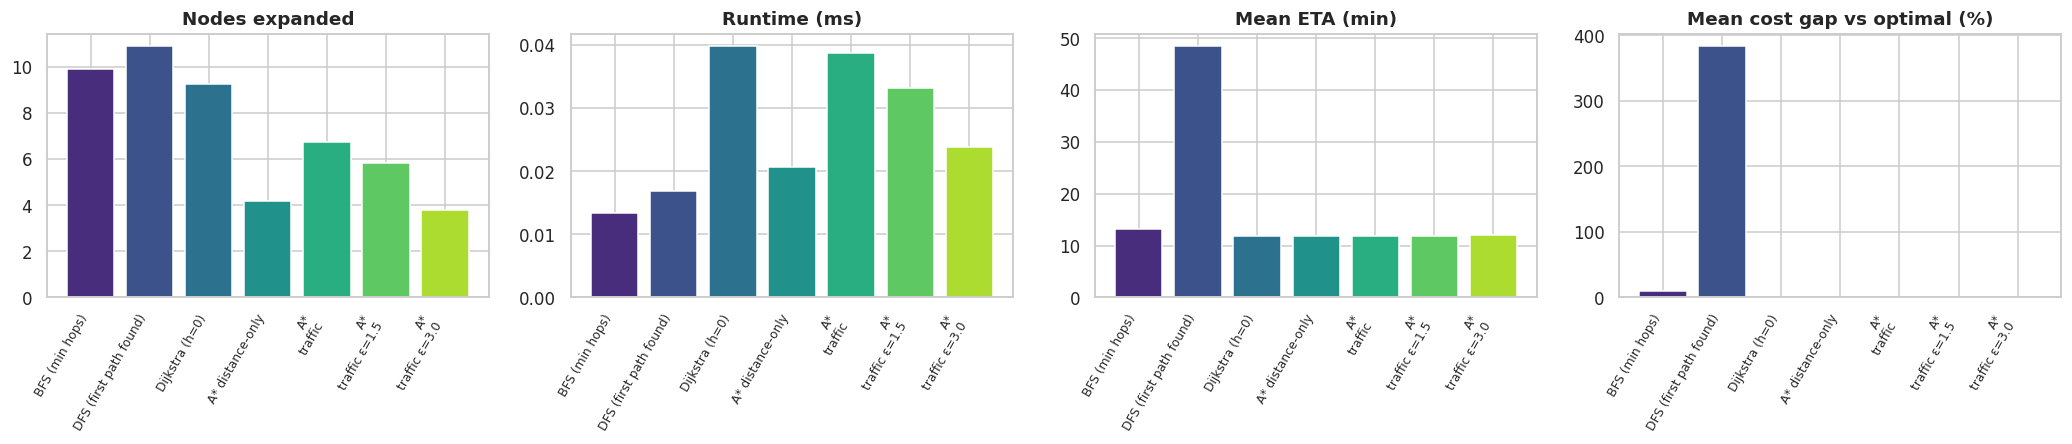

#### Cost-weight sensitivity (α, β, γ, δ) for one trip — routes are optimal *only for the stated objective*

,objective,route,distance_km,ETA_min,high/severe segs,nodes_expanded
0,Shortest distance,A→F→G→K→P,16.90,23.77,0,10
1,Fastest (ETA only),A→F→J→O→P,16.98,23.68,0,11
2,Balanced (default),A→F→G→K→P,16.90,23.77,0,16
3,Avoid congestion,A→F→G→K→P,16.90,23.77,0,16
4,Safety first,A→F→J→O→P,16.98,23.68,0,16


In [ ]:
def timed(fn, repeat=3):
    best, res = None, None
    for _ in range(repeat):
        r = fn(); best = r['runtime_ms'] if best is None else min(best, r['runtime_ms']); res = r
    res['runtime_ms'] = best; return res

METHODS = {
    'BFS (min hops)':           lambda G, s, t, W: bfs(G, s, t),
    'DFS (first path found)':   lambda G, s, t, W: dfs(G, s, t),
    'Dijkstra (h=0)':           lambda G, s, t, W: astar(G, s, t, 'cost'),
    'A* distance-only':         lambda G, s, t, W: astar(G, s, t, 'dist', make_h(G, t, 'dist', W)),
    'A* traffic-aware':         lambda G, s, t, W: astar(G, s, t, 'cost', make_h(G, t, 'cost', W)),
    'A* traffic-aware ε=1.5':   lambda G, s, t, W: astar(G, s, t, 'cost', make_h(G, t, 'cost', W), eps=1.5),
    'A* traffic-aware ε=3.0':   lambda G, s, t, W: astar(G, s, t, 'cost', make_h(G, t, 'cost', W), eps=3.0),
}
rows = []
for s_, t_ in itertools.combinations(NAMES, 2):
    ref_cost = evaluate_path(G_lab, astar(G_lab, s_, t_, 'cost', make_h(G_lab, t_, 'cost', DEFAULT_W))['path'])['cost']
    for name, fn in METHODS.items():
        r = timed(lambda: fn(G_lab, s_, t_, DEFAULT_W)); ev = evaluate_path(G_lab, r['path'])
        rows.append(dict(method=name, src=s_, dst=t_, expanded=r['expanded'], generated=r['generated'], runtime_ms=r['runtime_ms'],
                         gap_pct=100 * (ev['cost'] / ref_cost - 1), **ev))
lab_raw = pd.DataFrame(rows)
lab = lab_raw.groupby('method', sort=False).agg(nodes_expanded=('expanded', 'mean'), nodes_generated=('generated', 'mean'), runtime_ms=('runtime_ms', 'mean'),
                                                hops=('hops', 'mean'), distance_km=('distance_km', 'mean'), eta_min=('eta_min', 'mean'), route_cost=('cost', 'mean'),
                                                high_severe_segments=('n_high_severe', 'mean'), mean_gap_pct=('gap_pct', 'mean'),
                                                pct_pairs_optimal=('gap_pct', lambda g: 100 * (g < 1e-7).mean()))
md_out(f'Averages over **{lab_raw.groupby("method").size().iloc[0]} node pairs** (costs evaluated under the *same* traffic-aware objective; scenario {SC0}):')
display(lab.round(3)); lab.to_csv(f'{ROOT}/outputs/reports/algorithm_lab.csv')

fig, ax = plt.subplots(1, 4, figsize=(19, 4.2)); labs = [m.replace(' traffic-aware', '\ntraffic') for m in lab.index]
for a_, col, ttl in zip(ax, ['nodes_expanded', 'runtime_ms', 'eta_min', 'mean_gap_pct'], ['Nodes expanded', 'Runtime (ms)', 'Mean ETA (min)', 'Mean cost gap vs optimal (%)']):
    a_.bar(range(len(lab)), lab[col], color=sns.color_palette('viridis', len(lab))); a_.set_xticks(range(len(lab))); a_.set_xticklabels(labs, rotation=60, ha='right', fontsize=8); a_.set_title(ttl)
plt.tight_layout(); show('algorithm_lab')

md_out('#### Cost-weight sensitivity (α, β, γ, δ) for one trip — routes are optimal *only for the stated objective*')
S_, T_ = 'A', 'P'
WSETS = {'Shortest distance': dict(alpha=1, beta=0, gamma=0, delta=0), 'Fastest (ETA only)': dict(alpha=0, beta=1, gamma=0, delta=0),
         'Balanced (default)': DEFAULT_W, 'Avoid congestion': dict(alpha=.1, beta=.5, gamma=5, delta=1), 'Safety first': dict(alpha=.1, beta=.5, gamma=1, delta=5)}
srows = []
for nm, Wx in WSETS.items():
    Gx = annotate(G0, scen0, Wx); r = astar(Gx, S_, T_, 'cost', make_h(Gx, T_, 'cost', Wx)); ev = evaluate_path(Gx, r['path'])
    srows.append({'objective': nm, 'route': '→'.join(r['path']), 'distance_km': ev['distance_km'], 'ETA_min': ev['eta_min'], 'high/severe segs': ev['n_high_severe'], 'nodes_expanded': r['expanded']})
display(pd.DataFrame(srows).round(2))

## 13 · AI Decision Engine — prediction + routing → explainable recommendation
Combines the ML layer (predicted volume/speed/travel-time/congestion per sensor) with the graph layer, compares **top-k candidate routes** against the **distance-only** and **min-hop (BFS)** alternatives, and explains the choice. Includes a **simulated live incident** that forces re-routing and a **departure-time advisor**.

#### Scenario: Thursday 17:00, Rainy

Recommended route A → P: A → F → G → K → P
  • ETA 23.8 min over 16.9 km (4 segments); worst predicted segment: Medium; High/Severe segments: 0
  • Same as the shortest-distance route — no traffic-driven detour is worthwhile right now.
  • vs minimum-hop route (BFS, A→D→H→K→P): ETA 32.7 min
  • A* expanded 16 nodes (Dijkstra would use 16).
  • Objective: cost = 0.3·dist + 1.0·time + 1.0·congestion + 1.0·risk. This is the lowest-cost route FOR THIS OBJECTIVE, not a universally optimal one.
  • Basis: ML predictions from KAGGLE historical data — offline prototype, not live traffic.


,rank,route,distance_km,ETA_min,cost,high/severe segs
0,1,A→F→G→K→P,16.90,23.77,65.44,0
1,2,A→F→J→O→P,16.98,23.68,67.47,0
2,3,A→B→C→G→K→P,17.53,24.71,68.77,0


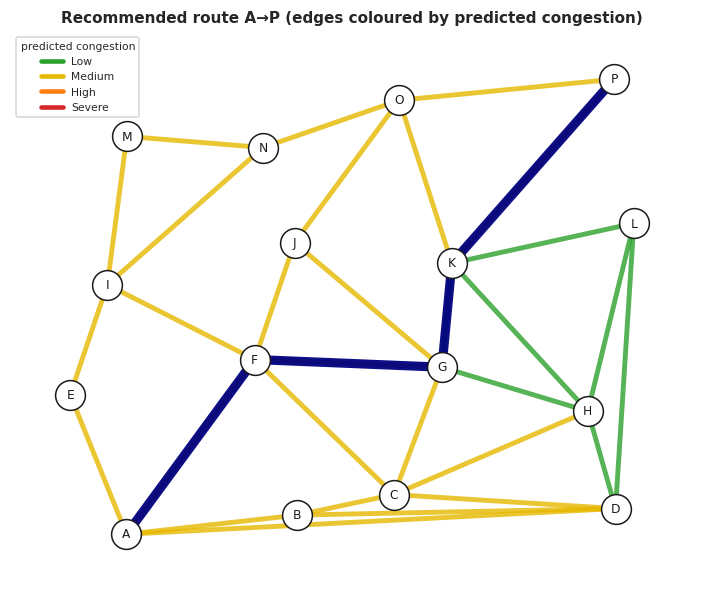

In [ ]:
def draw_network(Gs, routes=(), title='', ax=None):
    if ax is None: _, ax = plt.subplots(figsize=(8, 6.5))
    nx.draw_networkx_edges(Gs, POS, ax=ax, edge_color=[CONG_COLORS[Gs[u][v]['level']] for u, v in Gs.edges], width=3.2, alpha=.8)
    for path, color, ls, w in routes:
        nx.draw_networkx_edges(Gs, POS, ax=ax, edgelist=list(zip(path[:-1], path[1:])), edge_color=color, width=w, style=ls, alpha=.95)
    nx.draw_networkx_nodes(Gs, POS, ax=ax, node_color='white', edgecolors='k', node_size=380); nx.draw_networkx_labels(Gs, POS, ax=ax, font_size=8)
    ax.legend(handles=[plt.Line2D([0], [0], color=CONG_COLORS[l], lw=3, label=l) for l in LEVELS], title='predicted congestion', loc='upper left', fontsize=7, title_fontsize=7)
    ax.set_title(title, fontsize=10); ax.axis('off'); return ax

def recommend(src, dst, hour=17, day='Thursday', weather=None, temperature=None, humidity=None, signal=None,
              W=None, incidents=(), k=3, verbose=True, draw=True):
    assert src != dst and src in NAMES and dst in NAMES
    W = W or DEFAULT_W; weather = weather or DEFAULT_WEATHER
    scen = scenario_table(hour, day, weather, temperature, humidity, signal)
    Gs = annotate(G0, scen, W, frozenset(frozenset(e) for e in incidents))
    best = astar(Gs, src, dst, 'cost', make_h(Gs, dst, 'cost', W)); ev = evaluate_path(Gs, best['path'])
    cands = [(p, evaluate_path(Gs, p)) for p in itertools.islice(nx.shortest_simple_paths(Gs, src, dst, weight='cost'), k)]
    assert math.isclose(cands[0][1]['cost'], ev['cost'], rel_tol=1e-9)
    dist_only = astar(Gs, src, dst, 'dist', make_h(Gs, dst, 'dist', W)); ev_d = evaluate_path(Gs, dist_only['path'])
    hop = bfs(Gs, src, dst); ev_h = evaluate_path(Gs, hop['path'])
    table = pd.DataFrame([{'rank': i + 1, 'route': '→'.join(p), 'distance_km': e['distance_km'], 'ETA_min': e['eta_min'], 'cost': e['cost'], 'high/severe segs': e['n_high_severe']}
                          for i, (p, e) in enumerate(cands)])
    seg_lv = [Gs[u][v]['level'] for u, v in zip(best['path'][:-1], best['path'][1:])]
    worst = max(seg_lv, key=LEVELS.index)
    saved = ev_d['eta_min'] - ev['eta_min']
    lines = [f'Recommended route {src} → {dst}: {" → ".join(best["path"])}',
             f'  • ETA {ev["eta_min"]:.1f} min over {ev["distance_km"]:.1f} km ({ev["hops"]} segments); worst predicted segment: {worst}; High/Severe segments: {ev["n_high_severe"]}',
             (f'  • vs shortest-distance route ({"→".join(dist_only["path"])}): {"saves" if saved > 0 else "costs"} {abs(saved):.1f} min ETA, '
              f'{ev_d["n_high_severe"] - ev["n_high_severe"]:+d} fewer High/Severe segments' if dist_only['path'] != best['path'] else '  • Same as the shortest-distance route — no traffic-driven detour is worthwhile right now.'),
             f'  • vs minimum-hop route (BFS, {"→".join(hop["path"])}): ETA {ev_h["eta_min"]:.1f} min',
             f'  • A* expanded {best["expanded"]} nodes (Dijkstra would use {astar(Gs, src, dst, "cost")["expanded"]}).',
             f'  • Objective: cost = {W["alpha"]}·dist + {W["beta"]}·time + {W["gamma"]}·congestion + {W["delta"]}·risk. This is the lowest-cost route FOR THIS OBJECTIVE, not a universally optimal one.',
             f'  • Basis: ML predictions from {DATA_SOURCE.split(" (")[0]} historical data — offline prototype, not live traffic.']
    if verbose:
        md_out(f'#### Scenario: {day} {hour:02d}:00, {weather}' + (f' | incidents on {list(incidents)}' if incidents else ''))
        print('\n'.join(lines)); display(table.round(2))
    if draw:
        draw_network(Gs, [(best['path'], 'navy', '-', 6)], f'Recommended route {src}→{dst} (edges coloured by predicted congestion)')
        show(f'route_{src}_{dst}')
    return dict(Gs=Gs, scen=scen, best=best, eval=ev, table=table, dist_only=ev_d, hop=ev_h, text='\n'.join(lines))

R = recommend('A', 'P', **SC0)

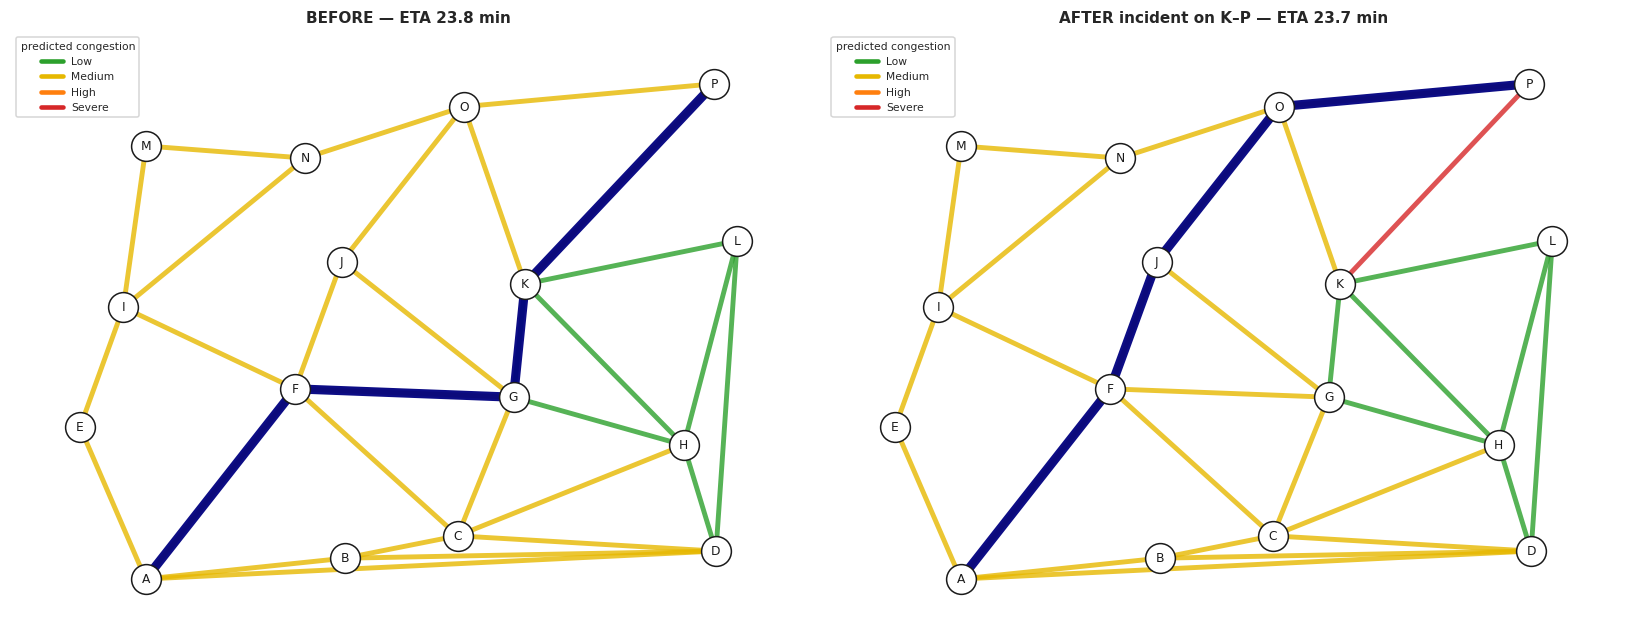

Route changed: True | A→F→G→K→P became A→F→J→O→P
ETA change: -0.1 min (ETA of the ORIGINAL route under the new conditions: 40.0 min)


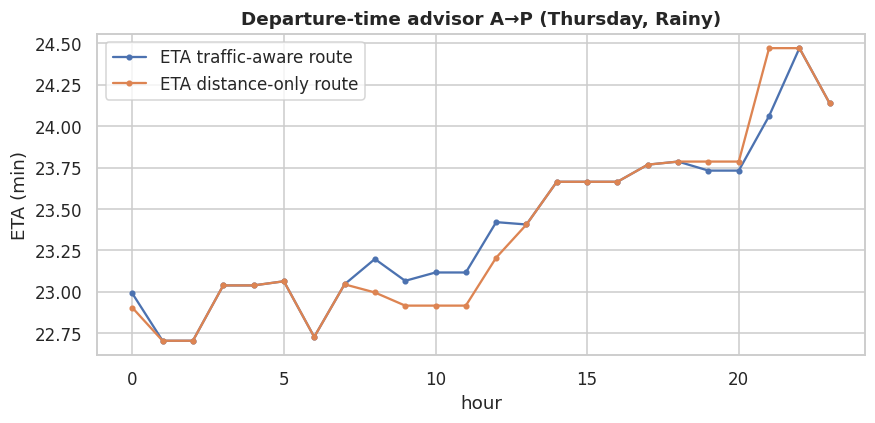

Lowest predicted ETA for this trip: hour 01:00 (22.7 min); highest: hour 22:00 (24.5 min)


In [ ]:
# ---- simulated LIVE update: an incident appears on the busiest segment of the recommended route ----
Gs = R['Gs']; path = R['best']['path']
worst_edge = max(zip(path[:-1], path[1:]), key=lambda uv: Gs[uv[0]][uv[1]]['time'])
R2 = recommend('A', 'P', **SC0, incidents=[worst_edge], verbose=False, draw=False)
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
draw_network(R['Gs'], [(R['best']['path'], 'navy', '-', 6)], f'BEFORE — ETA {R["eval"]["eta_min"]:.1f} min', ax[0])
draw_network(R2['Gs'], [(R2['best']['path'], 'navy', '-', 6)], f'AFTER incident on {worst_edge[0]}–{worst_edge[1]} — ETA {R2["eval"]["eta_min"]:.1f} min', ax[1])
plt.tight_layout(); show('live_incident_reroute')
print('Route changed:', R['best']['path'] != R2['best']['path'], '|', '→'.join(R['best']['path']), 'became', '→'.join(R2['best']['path']))
print(f'ETA change: {R2["eval"]["eta_min"] - R["eval"]["eta_min"]:+.1f} min (ETA of the ORIGINAL route under the new conditions: {evaluate_path(R2["Gs"], R["best"]["path"])["eta_min"]:.1f} min)')

# ---- departure-time advisor ----
adv = []
for hr in range(24):
    sc = scenario_table(hr, SC0['day'], SC0['weather']); Gx = annotate(G0, sc, DEFAULT_W)
    a = astar(Gx, 'A', 'P', 'cost', make_h(Gx, 'P', 'cost', DEFAULT_W)); dd = astar(Gx, 'A', 'P', 'dist', make_h(Gx, 'P', 'dist', DEFAULT_W))
    adv.append({'hour': hr, 'ETA traffic-aware route': evaluate_path(Gx, a['path'])['eta_min'], 'ETA distance-only route': evaluate_path(Gx, dd['path'])['eta_min']})
adv = pd.DataFrame(adv).set_index('hour')
adv.plot(figsize=(9, 3.8), marker='o', ms=3); plt.ylabel('ETA (min)'); plt.title(f'Departure-time advisor A→P ({SC0["day"]}, {SC0["weather"]})'); show('departure_advisor')
print(f'Lowest predicted ETA for this trip: hour {int(adv["ETA traffic-aware route"].idxmin()):02d}:00 ({adv["ETA traffic-aware route"].min():.1f} min); highest: hour {int(adv["ETA traffic-aware route"].idxmax()):02d}:00 ({adv["ETA traffic-aware route"].max():.1f} min)')

In [ ]:
# ---- interactive (zoom/hover) map-style view with Plotly ----
try:
    import plotly.graph_objects as go
    Gs = R['Gs']; fig = go.Figure()
    for u, v, e in Gs.edges(data=True):
        fig.add_trace(go.Scatter(x=[POS[u][0], POS[v][0]], y=[POS[u][1], POS[v][1]], mode='lines', line=dict(width=4, color=CONG_COLORS[e['level']]),
                                 hoverinfo='text', text=f"{u}–{v}<br>sensor {e['location_id']}<br>{e['level']} · {e['speed']:.0f} km/h<br>{e['dist']:.1f} km · {e['time']:.1f} min", showlegend=False))
    px_, py_ = zip(*[POS[n] for n in R['best']['path']])
    fig.add_trace(go.Scatter(x=px_, y=py_, mode='lines', line=dict(width=9, color='rgba(0,0,128,.55)'), name='recommended route'))
    fig.add_trace(go.Scatter(x=[POS[n][0] for n in NAMES], y=[POS[n][1] for n in NAMES], mode='markers+text', text=NAMES, textposition='top center',
                             marker=dict(size=14, color='white', line=dict(width=2, color='black')), showlegend=False, hoverinfo='skip'))
    fig.update_layout(title='Interactive road network — hover for predicted speed / ETA', height=560, yaxis=dict(scaleanchor='x', visible=False), xaxis=dict(visible=False), template='plotly_white')
    fig.show()
except ImportError:
    print('plotly not installed — skipping interactive map.')

## 14 · Interactive ITS dashboard (Colab widgets)
Pick source, destination, hour, weekday, weather — optionally inject an incident — and press **Plan route**.

#### Scenario: Thursday 17:00, Rainy

Recommended route A → P: A → F → G → K → P
  • ETA 23.8 min over 16.9 km (4 segments); worst predicted segment: Medium; High/Severe segments: 0
  • Same as the shortest-distance route — no traffic-driven detour is worthwhile right now.
  • vs minimum-hop route (BFS, A→D→H→K→P): ETA 32.7 min
  • A* expanded 16 nodes (Dijkstra would use 16).
  • Objective: cost = 0.3·dist + 1.0·time + 1.0·congestion + 1.0·risk. This is the lowest-cost route FOR THIS OBJECTIVE, not a universally optimal one.
  • Basis: ML predictions from KAGGLE historical data — offline prototype, not live traffic.


,rank,route,distance_km,ETA_min,cost,high/severe segs
0,1,A→F→G→K→P,16.90,23.77,65.44,0
1,2,A→F→J→O→P,16.98,23.68,67.47,0
2,3,A→B→C→G→K→P,17.53,24.71,68.77,0


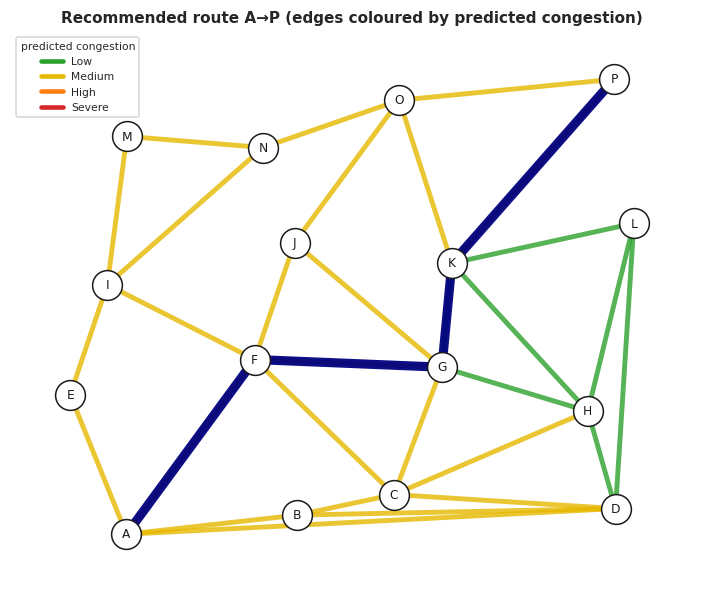

,pred_volume,pred_speed_kmh,tt_min_per_km,level,risk,segment_km
sensor,,,,,,
1,557.15,50.55,1.35,Medium,1.01,3.82
2,547.11,50.55,1.40,Medium,1.50,2.82
3,538.36,50.55,1.29,Medium,1.08,4.08
4,547.11,50.15,1.43,Low,1.32,3.59
5,547.11,50.55,1.45,Medium,1.48,1.78


In [ ]:
try:
    import ipywidgets as widgets
    w_src = widgets.Dropdown(options=NAMES, value='A', description='From:'); w_dst = widgets.Dropdown(options=NAMES, value='P', description='To:')
    w_hour = widgets.IntSlider(value=17, min=0, max=23, description='Hour:'); w_day = widgets.Dropdown(options=list(DAY_TO_DOW), value='Thursday', description='Day:')
    w_wx = widgets.Dropdown(options=WEATHERS, value=DEFAULT_WEATHER, description='Weather:')
    w_inc = widgets.Checkbox(value=False, description='Simulate incident on busiest segment'); w_btn = widgets.Button(description='Plan route', button_style='primary', icon='road')
    out = widgets.Output()
    def on_click(_):
        with out:
            clear_output(wait=True)
            if w_src.value == w_dst.value: print('Choose different source and destination.'); return
            base = recommend(w_src.value, w_dst.value, w_hour.value, w_day.value, w_wx.value, verbose=False, draw=False)
            inc = []
            if w_inc.value:
                p_ = base['best']['path']; inc = [max(zip(p_[:-1], p_[1:]), key=lambda uv: base['Gs'][uv[0]][uv[1]]['time'])]
            res = recommend(w_src.value, w_dst.value, w_hour.value, w_day.value, w_wx.value, incidents=inc)
            sc = res['scen'].copy(); sc['segment_km'] = SEG_KM.reindex(sc.index); display(sc.round(2).rename_axis('sensor'))
    w_btn.on_click(on_click)
    display(widgets.VBox([widgets.HBox([w_src, w_dst]), widgets.HBox([w_hour, w_day, w_wx]), widgets.HBox([w_inc, w_btn]), out]))
    on_click(None)
except ImportError:
    print('ipywidgets not available — call recommend("A","P",hour=8,day="Monday") manually.')

## 15 · Final evaluation, artefacts & export
Every number here is read from the objects computed above.

In [ ]:
def _f(x): return float(x) if x is not None and not (isinstance(x, float) and np.isnan(x)) else None
summary = {'data_source': DATA_SOURCE, 'data_file': str(DATA_PATH), 'rows_raw': int(len(raw)), 'rows_clean': int(len(d)), 'preprocessing': prep,
           'split': {'train_rows': int(d.is_train.sum()), 'test_rows': int((~d.is_train).sum()), 'split_timestamp': str(CUT_TS)},
           'regression': {}, 'classification': {}, 'clustering': {'k': int(K_BEST), 'silhouette': _f(max(sil))},
           'forecasting': {'best_model': BEST_FC, **{k: _f(v) for k, v in fc_table.loc[BEST_FC].items()}},
           'routing_lab': {m: {c: _f(v) for c, v in row.items()} for m, row in lab.iterrows()}}
reg_rows = []
for t_, r_ in REG.items():
    b = r_['table'][r_['table'].Model == r_['name']].iloc[0]; base = r_['table'][r_['table'].Model == 'Baseline (mean)'].iloc[0]
    summary['regression'][t_] = {'best_model': r_['name'], **{k: _f(b[k]) for k in ['MAE', 'MSE', 'RMSE', 'R2']}, 'baseline_RMSE': _f(base.RMSE)}
    reg_rows.append({'target': t_, 'best_model': r_['name'], **{k: b[k] for k in ['MAE', 'MSE', 'RMSE', 'R2']}, 'baseline_RMSE': base.RMSE})
clf_rows = []
for s_, r_ in CLF.items():
    b = r_['table'][r_['table'].Model == r_['name']].iloc[0]
    summary['classification'][s_] = {'best_model': r_['name'], **{k: _f(b[k]) for k in ['Accuracy', 'Precision(macro)', 'Recall(macro)', 'F1(macro)', 'BalancedAcc']}}
    clf_rows.append({'mode': s_, 'best_model': r_['name'], **{k: b[k] for k in ['Accuracy', 'Precision(macro)', 'Recall(macro)', 'F1(macro)', 'BalancedAcc']}})

md_out(f'### Results summary — data source: **{DATA_SOURCE}**')
display(pd.DataFrame(reg_rows).round(4)); display(pd.DataFrame(clf_rows).round(4)); display(fc_table.round(3).head(3))
if 'SYNTHETIC' in DATA_SOURCE:
    md_out('> ⚠️ **These numbers come from the synthetic fallback data (structured on purpose), so they will look better than results on the Kaggle file.** Re-run with the real Kaggle download for report-ready results.')

with open(f'{ROOT}/outputs/reports/summary.json', 'w') as fh: json.dump(summary, fh, indent=2, default=str)
with open(f'{ROOT}/outputs/reports/summary.md', 'w') as fh:
    fh.write(f'# ITS-AI results\n\nData source: {DATA_SOURCE}\n\n## Regression\n{pd.DataFrame(reg_rows).round(4).to_markdown(index=False)}\n\n'
             f'## Classification\n{pd.DataFrame(clf_rows).round(4).to_markdown(index=False)}\n\n## Forecasting\n{fc_table.round(3).to_markdown()}\n\n'
             f'## Routing lab\n{lab.round(3).to_markdown()}\n')
nx.set_node_attributes(G0, {n: {'x': POS[n][0], 'y': POS[n][1]} for n in NAMES})
with open(f'{ROOT}/models/road_graph.json', 'w') as fh: json.dump(nx.node_link_data(G0), fh, default=str)
loc_stats.to_csv(f'{ROOT}/data/processed/sensor_statistics.csv')

zpath = 'ITS-AI_outputs.zip'
with zipfile.ZipFile(zpath, 'w', zipfile.ZIP_DEFLATED) as z:
    for folder, _, files in os.walk(ROOT):
        for f in files: z.write(os.path.join(folder, f))
print(f'📦 Everything saved under ./{ROOT}/ and zipped to {zpath}')
try:
    from google.colab import files as colab_files; colab_files.download(zpath)
except ImportError:
    pass

### Results summary — data source: **KAGGLE (real download)**

,target,best_model,MAE,MSE,RMSE,R2,baseline_RMSE
0,traffic_volume,HistGB (tuned),245.2109,80227.3587,283.2443,-0.0282,279.3831
1,avg_speed,HistGB (tuned),15.5401,319.6682,17.8793,-0.0507,17.6436
2,travel_time_min,HistGB (tuned),1.5411,3.8694,1.9671,0.2082,2.2213


,mode,best_model,Accuracy,Precision(macro),Recall(macro),F1(macro),BalancedAcc
0,forecast,HistGradientBoosting,0.2900,0.2309,0.2321,0.2276,0.2321
1,nowcast,HistGradientBoosting,0.5175,0.5015,0.4674,0.4520,0.4674


,MAE,RMSE,MAPE_%
"ARIMA(0, 1, 1)",55.567,60.422,10.184
Moving average (w=24),55.567,60.437,10.162
Holt-Winters,55.567,60.517,10.124


📦 Everything saved under ./ITS-AI/ and zipped to ITS-AI_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## ✅ Roadmap coverage checklist
| Blueprint requirement | Where |
|---|---|
| Clean + audit data (missing, duplicates, summary) | §1.2, §2 |
| Mean/median/mode/range/variance/std/quartiles/percentiles | §4.1 |
| Correlation + covariance; hypothesis tests | §4.2, §4.3 |
| 8 required EDA charts | §4.4 |
| Regression: volume, speed, travel time (MAE/MSE/RMSE/R², actual-vs-pred, residuals) | §5 |
| Classification: Low/Medium/High/Severe (accuracy/precision/recall/F1/confusion matrix) | §6 |
| K-Means, PCA (+ anomaly detection) | §7 |
| Forecasting (Moving average / ARIMA / more) | §8 |
| Linear vs Binary search on sorted data | §9 |
| Road graph; BFS, DFS, A*; admissible heuristic; traffic-aware cost | §10–§12 |
| Distance-only vs traffic-aware comparison; heuristic experiments (ε-weighted A*) | §12 |
| Decision engine, explainability (permutation importance), simulated live updates | §5, §13 |
| Map-style visualisation + dashboard | §13, §14 |

**Next steps for the team:** swap the simulated graph for a real OSM/road network (`osmnx`), calibrate the α/β/γ/δ weights, port §14 to Streamlit (`dashboard/app.py`), and load the saved `.joblib` models from `ITS-AI/models/`.